# 58. Coarse-focused 6D calibration fine-tuning on KAIST

Continuation of **Notebook 57**. Starts from the best trained **6D regression checkpoint**, not the original 3D feature weights or a fresh head. All Transformer, pooler, MLP and 6D head weights remain trainable. The architecture, target convention, physical augmentation, translation/time-offset supervision, and train/val/test sequences are unchanged.

**Training distribution:** 80% rotation faults have a uniformly sampled angle from **120° to 179°**; 20% retain the original fine Student-t rotation distribution up to 60°, protecting small-angle behavior. The coarse minimum is enforced in the **shared augmentation sampler**, not by manually scaling a sampled rotation. Only one sensor's prior is faulted per example. No topology or artificial measurement-noise augmentation.

**Workflow:** Configure → inspect initial checkpoints and angle probes → reversible 1,000-step stochastic preflight using **exactly the intended training distribution and objective** → compare one-step errors → run **64-case-per-angle matched chronological feedback rollouts** (baseline 6D vs stochastic candidate) → decide whether to enable full 25-epoch training. The preflight restores the starting weights and random-number-generator state. The full training is **disabled by default**. If enabled later, the same rollout appendix compares the baseline checkpoint to the full-run best checkpoint.

Do not evaluate on Urban38/39 until final testing is deliberately enabled. Generated files are written only into a new run directory.


## 1. Imports, repository root and 6D module availability

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
from collections import defaultdict
import gc
import math
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run from the nn-obs-calib repository or a descendant directory.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.geometry.rotation_6d import matrix_to_rotation_6d, rotation_6d_to_matrix
from obscalib.models.pooled_calibration_6d_model import PooledCalibration6DModel, load_6d_pretrained_features
from obscalib.calibration.rotation_6d_update import apply_calibration_6d_update
from obscalib.training.rotation_6d_loss import Calibration6DLossWeights, calibration_6d_loss
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print('Repository:', ROOT, '| Torch:', torch.__version__, '| CUDA:', torch.cuda.is_available())


Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | Torch: 2.7.1+cu126 | CUDA: True


## 2. Configuration and training/validation policy

In [24]:
RUN_NAME = 'kaist_pooled_calibration_6d_002.28_coarse_120_179_finetune'
RUN_DIR = ROOT / 'runs' / RUN_NAME
BASELINE_6D_RUN_NAME = 'kaist_pooled_calibration_6d_002.27_full_rotation_regression'
BASELINE_6D_CHECKPOINT = ROOT / 'runs' / BASELINE_6D_RUN_NAME / 'best.pt'
# Always initialize the complete 6D model from its trained predecessor, not a new head.
INIT_6D_CHECKPOINT = BASELINE_6D_CHECKPOINT

RANDOM_SEED, TRAIN_AUG_SEED, VAL_AUG_SEED, TEST_AUG_SEED = 12345, 23456, 34567, 45678
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DTYPE = torch.float32
CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5.0, 5.0, 700
BATCH_SIZE, NUM_WORKERS, GRADIENT_ACCUMULATION_STEPS = 16, 0, 1
NUM_EPOCHS, WEIGHT_DECAY, GRADIENT_CLIP_NORM = 50, 1e-4, 1.0
HEAD_MLP_LR = 5e-5
TRANSFORMER_LR = HEAD_MLP_LR / 10.0
LR_REDUCE_FACTOR, LR_PATIENCE_EPOCHS = 0.5, 10
RUN_FULL_TRAINING = True
RESUME_FULL_TRAINING = False
MAX_TRAIN_BATCHES_PER_EPOCH, MAX_VAL_BATCHES_PER_EPOCH = None, None

MEASUREMENT_DIM, TOKEN_INPUT_DIM = 6, 8
D_MODEL, N_HEADS, NUM_TRANSFORMER_LAYERS, DIM_FEEDFORWARD = 128, 8, 12, 512
TRANSFORMER_DROPOUT, NUM_SUMMARY_TOKENS = 0.0, 1
POOLER_N_HEADS, POOLER_DROPOUT = 8, 0.0
MLP_HIDDEN_DIMS, SHARED_FEATURE_DIM, MLP_DROPOUT = (256, 128), 128, 0.0
HEAD_HIDDEN_DIMS, HEAD_DROPOUT = (128, 64), 0.0

# Original notebook 47 tau references (all three physical sensor streams remain present).
REFINED_TAU_BY_SENSOR_S = {'imu': 0.0, 'lidar': -0.025, 'lidar_right': -0.035}
TRUE_CALIBRATION_ROTATION_MAX_RAD = np.deg2rad(180.0)
TRUE_CALIBRATION_TIME_OFFSET_MAX_S = 0.030

# Fine prior distribution retains Notebook 47's Student-t rotation/timing model.
FINE_ROTATION_MAX_DEG, FINE_ROTATION_SCALE_DEG = 60.0, 30.0
# Coarse faults are deliberately broad, not Student-t tails that almost never visit 175–179°.
COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG = 120.0, 179.0
COARSE_PRIOR_PROBABILITY = 0.80
PRIOR_TRANSLATION_MAX_M, PRIOR_TRANSLATION_SCALE_M = 0.05, 0.02
PRIOR_TAU_MAX_S, PRIOR_TAU_SCALE_S = 0.50, 0.25
STUDENT_T_DOF = 3
ACTIVE_ROTATION_SUPERVISION_WEIGHT = 0.75
LOSS_WEIGHTS = Calibration6DLossWeights(rotation_weight=2.0, rotation_6d_weight=1.0, rotation_chordal_weight=1.0, translation_weight=1.0, time_offset_weight=1.0, translation_scale_m=0.05, time_offset_scale_s=0.05)

# Fixed validation probe: model-selected checkpoint must work at coarse angles, not only lower val loss.
PROBE_ANGLES_DEG = (0.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
PROBE_FINE_SCORE_ANGLES_DEG = (30.0, 60.0, 90.0)
PROBE_COARSE_SCORE_ANGLES_DEG = (120.0, 150.0, 175.0, 179.0)
PROBE_SCORE_ANGLES_DEG = PROBE_FINE_SCORE_ANGLES_DEG + PROBE_COARSE_SCORE_ANGLES_DEG
PROBE_COARSE_SCORE_WEIGHT = 0.75
PROBE_WINDOWS, PROBE_BATCH_SIZE, PROBE_AXIS_SEEDS = 32, 8, 2
PROBE_FAULT_KEYS = ('lidar', 'lidar_right')
PROBE_EVERY_EPOCHS = 1
ZERO_DRIFT_WEIGHT = 0.15  # penalty in relative-score units: zero-angle drift / 30°
SHOW_PLOTS = True

KAIST_TAU_IMU_S = 0.0
KAIST_TAU_LIDAR_S = -0.025
KAIST_TAU_LIDAR_RIGHT_S = -0.035
REFINED_TAU_BY_SENSOR_S = {"imu": KAIST_TAU_IMU_S, "lidar": KAIST_TAU_LIDAR_S, "lidar_right": KAIST_TAU_LIDAR_RIGHT_S}
assert abs((KAIST_TAU_LIDAR_S - KAIST_TAU_IMU_S) * 1000 + 25.0) < 1e-8
assert abs((KAIST_TAU_LIDAR_RIGHT_S - KAIST_TAU_IMU_S) * 1000 + 35.0) < 1e-8

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700
NUM_WORKERS = 0
DROP_LAST_TRAIN = True

# Test data are kept untouched until consciously enabling final evaluation.
RUN_FINAL_TEST_EVALUATION = False

assert abs(TRANSFORMER_LR * 10.0 - HEAD_MLP_LR) < 1e-12
assert 0.0 < COARSE_ROTATION_MIN_DEG < COARSE_ROTATION_MAX_DEG < 180.0
assert 0 <= COARSE_PRIOR_PROBABILITY <= 1
assert set(PROBE_FAULT_KEYS).issubset(CALIBRATION_KEYS)
if not INIT_6D_CHECKPOINT.is_file():
    raise FileNotFoundError(f'Fully trained 6D initialization checkpoint not found: {INIT_6D_CHECKPOINT}')
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(RANDOM_SEED)
RUN_DIR.mkdir(parents=True, exist_ok=True)
print('Run:', RUN_DIR)
print('Learning rates: head/MLP/pooler=', HEAD_MLP_LR, '| Transformer=', TRANSFORMER_LR)
print('Single topology:', CALIBRATION_KEYS, '| no topology or artificial sensor-noise augmentation')

print('Coarse prior:', COARSE_PRIOR_PROBABILITY, 'of examples with rotation magnitude in', (COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG), 'degrees')
print('6D initialization:', INIT_6D_CHECKPOINT, '| full training enabled:', RUN_FULL_TRAINING)


Run: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.28_coarse_120_179_finetune
Learning rates: head/MLP/pooler= 5e-05 | Transformer= 5e-06
Single topology: ('imu', 'lidar', 'lidar_right') | no topology or artificial sensor-noise augmentation
Coarse prior: 0.8 of examples with rotation magnitude in (120.0, 179.0) degrees
6D initialization: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.27_full_rotation_regression/best.pt | full training enabled: True


## 3. KAIST data, splits and corrected timing reference (from Notebook 47)

In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

# Right LiDAR -> body, in the same convention as T_B_L for the left LiDAR.
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=KAIST_TAU_IMU_S, tau_lidar_s=KAIST_TAU_LIDAR_S, T_B_L_right=T_B_L_right, tau_lidar_right_s=KAIST_TAU_LIDAR_RIGHT_S)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)

print("train:", TRAIN_NAMES)
print("validation:", VAL_NAMES)
print("test:", TEST_NAMES)
print("Corrected rig τ [ms]:", {key: 1000.0 * value for key, value in REFINED_TAU_BY_SENSOR_S.items()})


train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
validation: ['Urban26', 'Urban28']
test: ['Urban38', 'Urban39']
Corrected rig τ [ms]: {'imu': 0.0, 'lidar': -25.0, 'lidar_right': -35.0}


In [4]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")

# The 3-sensor experiment must never silently fall back to 2 sensors.
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Missing required right-LiDAR pose CSV for {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

train_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TRAIN_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
val_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in VAL_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
test_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TEST_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

for split_name, dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"{split_name} dataset has calibration keys {dataset.calibration_keys}, expected {CALIBRATION_KEYS}")

print(train_dataset.summary())
print()
print(val_dataset.summary())
print()
print(test_dataset.summary())

# Check the actual WindowBatch ground truth, not just constructor arguments.
for split_name, split_dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    sample = collate_windows([split_dataset[0]])
    for sensor, expected_s in REFINED_TAU_BY_SENSOR_S.items():
        observed = float(sample.current_calibration[sensor].time_offset.reshape(-1)[0].item())
        assert abs(observed - expected_s) < 2e-6, f"{split_name}/{sensor}: dataset τ={observed} but expected {expected_s}"
    print(f"{split_name}: τ targets [ms] verified:", {sensor: round(float(state.time_offset.reshape(-1)[0]) * 1000, 3) for sensor, state in sample.current_calibration.items()})

# Compare the zero-clock and corrected-clock dataset instances on the same held-out
# physical windows. This checks whether the loader alters raw measurements when the
# rig reference changes; it never deliberately shifts raw timestamps in this notebook.
zero_clock_rig = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
zero_clock_control = KAISTCalibrationDataset([spec_by_name[TEST_NAMES[0]]], zero_clock_rig, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
corrected_control = KAISTCalibrationDataset([spec_by_name[TEST_NAMES[0]]], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
if len(zero_clock_control) != len(corrected_control):
    raise RuntimeError("Changing calibration τ modified the number of windows. Inspect dataset timestamp processing before training.")
for index in sorted({0, len(zero_clock_control)//2, len(zero_clock_control)-1}):
    old, new = zero_clock_control[index], corrected_control[index]
    for stream_name in old.streams:
        old_stream, new_stream = old.streams[stream_name], new.streams[stream_name]
        torch.testing.assert_close(old_stream.values, new_stream.values, rtol=0, atol=0)
        torch.testing.assert_close(old_stream.timestamps, new_stream.timestamps, rtol=0, atol=0)
        if old_stream.interval_start_timestamps is not None:
            torch.testing.assert_close(old_stream.interval_start_timestamps, new_stream.interval_start_timestamps, rtol=0, atol=0)
print("PASS: refined τ changes calibration reference while preserving native stream measurements and timestamps.")
del zero_clock_control, corrected_control


KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiD

In [5]:
train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=DROP_LAST_TRAIN, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)
test_loader = make_kaist_dataloader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

print("train batches:", len(train_loader))
print("validation batches:", len(val_loader))
print("test batches:", len(test_loader))


train batches: 125
validation batches: 27
test batches: 44


## 4. Physically consistent truth augmentation, fine/coarse *independent* prior faults

In [6]:
true_calibration_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0, time_offset_probability=1.0, rotation=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_ROTATION_MAX_RAD), time_offset=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_TIME_OFFSET_MAX_S)),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
physical_augmenter = AugmentationPipeline(true_calibration_config)

def prior_config(rotation_max_rad, rotation_distribution, rotation_scale_rad=None, *, rotation_min_rad=0.0):
    rotation_kwargs = dict(maximum=rotation_max_rad, minimum=rotation_min_rad, distribution=rotation_distribution)
    if rotation_distribution == PerturbationDistribution.TRUNCATED_STUDENT_T:
        rotation_kwargs.update(scale=rotation_scale_rad, degrees_of_freedom=STUDENT_T_DOF)
    return PriorPerturbationConfig(
        enabled=True, probability=1.0,
        rotation=PerturbationMagnitudeConfig(**rotation_kwargs),
        translation=PerturbationMagnitudeConfig(maximum=PRIOR_TRANSLATION_MAX_M, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=PRIOR_TRANSLATION_SCALE_M, degrees_of_freedom=STUDENT_T_DOF),
        time_offset=PerturbationMagnitudeConfig(maximum=PRIOR_TAU_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=PRIOR_TAU_SCALE_S, degrees_of_freedom=STUDENT_T_DOF),
        one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
    )

fine_prior_config = prior_config(np.deg2rad(FINE_ROTATION_MAX_DEG), PerturbationDistribution.TRUNCATED_STUDENT_T, np.deg2rad(FINE_ROTATION_SCALE_DEG))
coarse_prior_config = prior_config(np.deg2rad(COARSE_ROTATION_MAX_DEG), PerturbationDistribution.UNIFORM, rotation_min_rad=np.deg2rad(COARSE_ROTATION_MIN_DEG))
fine_prior_perturber = CalibrationPriorPerturber(fine_prior_config)
coarse_prior_perturber = CalibrationPriorPerturber(coarse_prior_config)


def augmentation_generator(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))


def clone_with_current_calibration(window, states):
    return WindowBatch(streams=dict(window.streams), current_calibration=states, metadata=dict(window.metadata), targets=window.targets, dataset_indices=window.dataset_indices)


def apply_independent_prior_faults(states, xi_by_key, tau_by_key):
    """Left-rotate only R; add independent parent-frame t and tau faults. Never rotate t with R."""
    updated = {}
    for key, state in states.items():
        xi = xi_by_key[key]
        prior = state.transform.clone()
        prior[:, :3, :3] = so3_exp(xi[:, :3]) @ state.transform[:, :3, :3]
        prior[:, :3, 3] = state.transform[:, :3, 3] + xi[:, 3:]
        updated[key] = replace(state, transform=prior, time_offset=state.time_offset + tau_by_key[key])
    return updated


@torch.no_grad()
def make_training_window(base_window, *, generator):
    """Physical augmentation followed by exactly one sensor's fine or coarse prior fault."""
    physical = physical_augmenter(base_window, generator=generator).augmented_window
    true_states = physical.current_calibration
    _, fine_xi, fine_tau = fine_prior_perturber(true_states, generator=generator)
    _, coarse_xi, coarse_tau = coarse_prior_perturber(true_states, generator=generator)
    batch_size = next(iter(true_states.values())).transform.shape[0]
    coarse_mask = torch.rand(batch_size, device=DEVICE, generator=generator) < COARSE_PRIOR_PROBABILITY
    # Coarse magnitudes are sampled directly from the configured [120°, 179°]
    # interval by the shared sampler. Do NOT rescale or re-sample coarse angles here.
    xi = {key: torch.where(coarse_mask[:, None], coarse_xi[key], fine_xi[key]) for key in true_states}
    tau = {key: torch.where(coarse_mask[:, None], coarse_tau[key], fine_tau[key]) for key in true_states}
    return clone_with_current_calibration(physical, apply_independent_prior_faults(true_states, xi, tau))


assert tuple(CALIBRATION_KEYS) == ('imu', 'lidar', 'lidar_right')
assert not true_calibration_config.sensor_topology.enabled
assert not true_calibration_config.frame_randomization.enabled
assert not true_calibration_config.common_body_frame.enabled
assert not true_calibration_config.noise.enabled
print('True-calibration re-expression enabled; topology/noise/frame augmentation disabled.')
print('Fine prior:', fine_prior_config)
print('Coarse prior:', coarse_prior_config)

# Distribution smoke test. This samples rotation magnitudes directly, without applying sensor masks.
from obscalib.augmentations.sampling import sample_perturbation_magnitudes
sampling_probe = sample_perturbation_magnitudes(coarse_prior_config.rotation, 4096, device=DEVICE, dtype=DTYPE, generator=augmentation_generator(TRAIN_AUG_SEED + 41414))
sampled_angles_deg = torch.rad2deg(sampling_probe).squeeze(-1)
assert bool((sampled_angles_deg >= COARSE_ROTATION_MIN_DEG - 1e-4).all())
assert bool((sampled_angles_deg <= COARSE_ROTATION_MAX_DEG + 1e-4).all())
assert coarse_prior_config.rotation.minimum > 0.0
print(f'Coarse sampler verified: {sampled_angles_deg.min().item():.3f}° to {sampled_angles_deg.max().item():.3f}° over 4096 draws')


True-calibration re-expression enabled; topology/noise/frame augmentation disabled.
Fine prior: PriorPerturbationConfig(enabled=True, probability=1.0, probability_by_key={}, rotation=PerturbationMagnitudeConfig(maximum=1.0471975511965976, distribution=<PerturbationDistribution.TRUNCATED_STUDENT_T: 'truncated_student_t'>, scale=0.5235987755982988, degrees_of_freedom=3, minimum=0.0), translation=PerturbationMagnitudeConfig(maximum=0.05, distribution=<PerturbationDistribution.TRUNCATED_STUDENT_T: 'truncated_student_t'>, scale=0.02, degrees_of_freedom=3, minimum=0.0), time_offset=PerturbationMagnitudeConfig(maximum=0.5, distribution=<PerturbationDistribution.TRUNCATED_STUDENT_T: 'truncated_student_t'>, scale=0.25, degrees_of_freedom=3, minimum=0.0), one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False)
Coarse prior: PriorPerturbationConfig(enabled=True, probability=1.0, probability_by_key={}, rotation=PerturbationMagnitudeConfig(maximu

## 5. Complete pretrained 6D regression model + small fine-tuning learning rates

The original Notebook 57 6D modules must exist under `src/obscalib/`. The entire trained 6D model, including the 10D head, is loaded from the previous run. All weights remain trainable. There is no new randomly initialized head.

In [7]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation='gelu'),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation='gelu', dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(n_heads=POOLER_N_HEADS, dropout=POOLER_DROPOUT, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=HEAD_HIDDEN_DIMS, activation='gelu', dropout=HEAD_DROPOUT),
)
geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)
model = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)
# Restore the complete trained 6D model (including its head); initialize a NEW optimizer later.
load_training_checkpoint(INIT_6D_CHECKPOINT, model=model, map_location=DEVICE, restore_rng_state=False)
print('Initialized all 6D model weights from:', INIT_6D_CHECKPOINT)
model.freeze_feature_extractor(False)
model.head_6d.requires_grad_(True)
assert all(p.requires_grad for p in model.parameters())


def model_predictions(window, *, model_override=None):
    """Reuse exactly the canonical GeometryProcessor/Tokenizer routing, no legacy SE3 updater."""
    if tuple(window.current_calibration) != CALIBRATION_KEYS:
        raise ValueError(f'Unexpected topology/order: {tuple(window.current_calibration)}')
    canonical_streams = geometry_processor(window.streams, window.metadata, window.current_calibration)
    tokens = tokenizer(canonical_streams, calibration_keys=tuple(window.current_calibration))
    return (model if model_override is None else model_override)(tokens)


def parameter_groups(module):
    transformer = list(module.transformer_encoder.parameters())
    other = list(module.pooler.parameters()) + list(module.mlp_body.parameters()) + list(module.head_6d.parameters())
    if len({id(p) for p in transformer + other}) != len(transformer + other):
        raise RuntimeError('Overlapping optimizer groups')
    if len(transformer + other) != len(list(module.parameters())):
        raise RuntimeError('Optimizer groups miss model parameters')
    return [dict(params=transformer, lr=TRANSFORMER_LR, name='transformer'), dict(params=other, lr=HEAD_MLP_LR, name='pooler_mlp_head')]


optimizer = torch.optim.AdamW(parameter_groups(model), weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=LR_REDUCE_FACTOR, patience=LR_PATIENCE_EPOCHS)
print('Parameters:', sum(p.numel() for p in model.parameters()), '| all trainable:', all(p.requires_grad for p in model.parameters()))
print('Learning rates:', [(group['name'], group['lr']) for group in optimizer.param_groups])


Initialized all 6D model weights from: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.27_full_rotation_regression/best.pt
Parameters: 2554570 | all trainable: True
Learning rates: [('transformer', 5e-06), ('pooler_mlp_head', 5e-05)]


## 6. Full-range objective, differentiable updates and numerical diagnostics

In [8]:
def rotation_geodesic_deg(R_first, R_second):
    """Numerically stable geodesic SO(3) angle, including near 180°. Shape [...]."""
    relative = R_first @ R_second.transpose(-1, -2)
    skew = torch.stack((relative[..., 2, 1] - relative[..., 1, 2], relative[..., 0, 2] - relative[..., 2, 0], relative[..., 1, 0] - relative[..., 0, 1]), dim=-1)
    sine = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cosine = 0.5 * (relative.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0)
    return torch.rad2deg(torch.atan2(sine, cosine))


def compute_6d_objective(window, output):
    """Joint 6D+chordal rotation loss, translation/tau loss, and active-fault emphasis."""
    if window.targets is None:
        raise ValueError('Training requires full GT targets')
    supervised = calibration_6d_loss(output.predictions, window.current_calibration, window.targets, weights=LOSS_WEIGHTS)
    active_terms, active_angle_errors, active_predicted_angles, active_target_angles = [], [], [], []
    for key in CALIBRATION_KEYS:
        state, truth, pred = window.current_calibration[key], window.targets[key], output.predictions[key]
        R_target = truth.next_transform[:, :3, :3] @ state.transform[:, :3, :3].transpose(-1, -2)
        angle_before = rotation_geodesic_deg(state.transform[:, :3, :3], truth.next_transform[:, :3, :3])
        active = angle_before > 1e-3
        if bool(active.any()):
            target_6d = matrix_to_rotation_6d(R_target)
            reg = (pred.rotation_6d - target_6d).square().mean(dim=-1)
            chord = 0.5 * (pred.delta_rotation - R_target).square().sum(dim=(-2, -1))
            active_terms.append((LOSS_WEIGHTS.rotation_6d_weight * reg + LOSS_WEIGHTS.rotation_chordal_weight * chord)[active])
            active_angle_errors.append(rotation_geodesic_deg(pred.delta_rotation[active], R_target[active]).detach())
            active_predicted_angles.append(rotation_geodesic_deg(pred.delta_rotation[active], torch.eye(3, device=DEVICE, dtype=DTYPE).expand_as(pred.delta_rotation[active])).detach())
            active_target_angles.append(angle_before[active].detach())
    extra_active = LOSS_WEIGHTS.rotation_weight * torch.cat(active_terms).mean() if active_terms else supervised.total * 0.0
    loss = supervised.total + ACTIVE_ROTATION_SUPERVISION_WEIGHT * extra_active
    with torch.no_grad():
        corrected = apply_calibration_6d_update(window.current_calibration, output.predictions)
        values = {}
        for key in CALIBRATION_KEYS:
            target = window.targets[key]
            state = corrected[key]
            values[f'{key}/rotation_error_deg'] = rotation_geodesic_deg(state.transform[:, :3, :3], target.next_transform[:, :3, :3]).mean().item()
            values[f'{key}/translation_error_cm'] = (100.0 * torch.linalg.vector_norm(state.transform[:, :3, 3] - target.next_transform[:, :3, 3], dim=-1)).mean().item()
            values[f'{key}/tau_error_ms'] = (1000.0 * (state.time_offset - target.next_time_offset).abs()).mean().item()
        values.update({'loss_total': float(loss.detach()), 'loss_supervised': float(supervised.total.detach()), 'loss_active_rotation': float(extra_active.detach()), 'loss_rotation_6d': float(supervised.rotation_6d.detach()), 'loss_rotation_chordal': float(supervised.rotation_chordal.detach()), 'loss_translation': float(supervised.translation.detach()), 'loss_tau': float(supervised.time_offset.detach()), 'active_rotation_error_deg': torch.cat(active_angle_errors).mean().item() if active_angle_errors else 0.0, 'active_target_deg': torch.cat(active_target_angles).mean().item() if active_target_angles else 0.0, 'active_predicted_step_deg': torch.cat(active_predicted_angles).mean().item() if active_predicted_angles else 0.0, 'active_rotation_count': sum(x.numel() for x in active_angle_errors)})
    return loss, values


def metric_average(sums, counts):
    return {key: sums[key] / counts[key] for key in sums}


## 7. Semantic and gradient smoke checks (including 179° target continuity)

In [9]:
smoke_base = window_batch_to(collate_windows([train_dataset[0], train_dataset[min(100, len(train_dataset) - 1)]]), DEVICE, dtype=DTYPE)
smoke_window = make_training_window(smoke_base, generator=augmentation_generator(TRAIN_AUG_SEED + 101))
assert tuple(smoke_window.current_calibration) == CALIBRATION_KEYS
assert set(smoke_window.streams) == set(smoke_base.streams)
for key, stream in smoke_window.streams.items():
    original = smoke_base.streams[key]
    assert stream.values.shape == original.values.shape
    assert bool(torch.isfinite(stream.values).all())
    assert bool(torch.isfinite(stream.timestamps).all())
    torch.testing.assert_close(stream.sample_mask, original.sample_mask)
for key in CALIBRATION_KEYS:
    target = smoke_window.targets[key]
    assert target.next_transform is not None and target.next_time_offset is not None
    R = smoke_window.current_calibration[key].transform[:, :3, :3]
    R_gt = target.next_transform[:, :3, :3]
    R_delta = R_gt @ R.transpose(-1, -2)
    torch.testing.assert_close(rotation_6d_to_matrix(matrix_to_rotation_6d(R_delta)), R_delta, atol=5e-5, rtol=5e-5)

model.train()
optimizer.zero_grad(set_to_none=True)
smoke_output = model_predictions(smoke_window)
smoke_loss, smoke_metrics = compute_6d_objective(smoke_window, smoke_output)
smoke_loss.backward()
for part in ('transformer_encoder', 'pooler', 'mlp_body', 'head_6d'):
    grads = [p.grad for p in getattr(model, part).parameters() if p.requires_grad and p.grad is not None]
    assert grads and all(bool(torch.isfinite(g).all()) for g in grads), f'{part}: missing/nonfinite gradients'
    print(part, 'grad norm', round(math.sqrt(sum(float(g.square().sum()) for g in grads)), 5))
assert torch.isfinite(smoke_loss) and smoke_metrics['active_rotation_count'] > 0
optimizer.zero_grad(set_to_none=True)
model.eval()
print('PASS: 6D gradients reach all unfrozen layers; supervised full-GT update is valid.')
print('Smoke loss:', round(smoke_metrics['loss_total'], 4), '| active geodesic error:', round(smoke_metrics['active_rotation_error_deg'], 2), 'deg')
del smoke_base, smoke_window, smoke_output, smoke_loss

# Check the ACTUAL composed augmentation distribution, not only the low-level sampler.
# The single faulted sensor must lie in either the fine (<60°) or coarse (120–179°) range.
with torch.no_grad():
    distribution_base = window_batch_to(next(iter(train_loader)), DEVICE, dtype=DTYPE)
    distribution_window = make_training_window(distribution_base, generator=augmentation_generator(TRAIN_AUG_SEED + 800001))
    sampled_angles_by_key = torch.stack([rotation_geodesic_deg(distribution_window.current_calibration[key].transform[:, :3, :3], distribution_window.targets[key].next_transform[:, :3, :3]) for key in CALIBRATION_KEYS], dim=1)
    active_counts = (sampled_angles_by_key > 1e-3).sum(dim=1)
    assert bool((active_counts <= 1).all()), 'Expected at most one rotation-faulted sensor per batch item'
    active_angles = sampled_angles_by_key[sampled_angles_by_key > 1e-3]
    legal = (active_angles <= FINE_ROTATION_MAX_DEG + 0.02) | ((active_angles >= COARSE_ROTATION_MIN_DEG - 0.02) & (active_angles <= COARSE_ROTATION_MAX_DEG + 0.02))
    assert bool(legal.all()), 'Some training rotations fell in the excluded 60–120° gap'
    print('Actual training rotation-fault counts:', int((active_angles <= FINE_ROTATION_MAX_DEG + 0.02).sum()), 'fine /', int((active_angles >= COARSE_ROTATION_MIN_DEG - 0.02).sum()), 'coarse')
    del distribution_base, distribution_window, sampled_angles_by_key


transformer_encoder grad norm 90.5704
pooler grad norm 10.83185
mlp_body grad norm 11.59878
head_6d grad norm 58.48805
PASS: 6D gradients reach all unfrozen layers; supervised full-GT update is valid.
Smoke loss: 7.4179 | active geodesic error: 119.93 deg
Actual training rotation-fault counts: 3 fine / 13 coarse


## 8. Fixed held-out angular probes and checkpoint score

Each probe repeats **the exact same augmented physical windows, rotation axes and prior faults** at every evaluation. Per-angle results are full-GT geodesic errors after *one uncapped 6D correction*, not velocity/CTG errors. The probe samples fault the two LiDARs while leaving other calibrations at GT to measure healthy-sensor drift. All methods see the same calibration convention.

In [10]:
@torch.no_grad()
def build_probe_batches(dataset, *, n_windows, batch_size, seed, angles=PROBE_ANGLES_DEG, axis_seeds=PROBE_AXIS_SEEDS):
    indices = np.unique(np.linspace(0, len(dataset) - 1, min(len(dataset), n_windows)).round().astype(int))
    batches = []
    for axis_seed in range(axis_seeds):
        for group_id, start in enumerate(range(0, len(indices), batch_size)):
            chosen = indices[start:start + batch_size]
            base = window_batch_to(collate_windows([dataset[int(i)] for i in chosen]), DEVICE, dtype=DTYPE)
            generator = augmentation_generator(seed + axis_seed * 100003 + group_id * 1009)
            physical = physical_augmenter(base, generator=generator).augmented_window
            n = len(chosen)
            template = next(iter(physical.current_calibration.values())).transform
            axes = torch.randn(n, 3, generator=generator, device=template.device, dtype=template.dtype)
            axes = axes / torch.linalg.vector_norm(axes, dim=-1, keepdim=True).clamp_min(1e-9)
            cases = {}
            for angle in angles:
                xi = {key: torch.zeros(n, 6, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                tau = {key: torch.zeros(n, 1, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                keys = [PROBE_FAULT_KEYS[(j + axis_seed) % len(PROBE_FAULT_KEYS)] for j in range(n)]
                for j, key in enumerate(keys):
                    xi[key][j, :3] = axes[j] * np.deg2rad(float(angle))
                prior = apply_independent_prior_faults(physical.current_calibration, xi, tau)
                cases[float(angle)] = (clone_with_current_calibration(physical, prior), keys, chosen.copy(), axis_seed)
            batches.append(cases)
    return batches


@torch.inference_mode()
def evaluate_probe(model_to_evaluate, batches):
    original_training = model_to_evaluate.training
    model_to_evaluate.eval()
    rows = []
    try:
        for cases in batches:
            for angle, (window, fault_keys, indices, axis_seed) in cases.items():
                output = model_predictions(window, model_override=model_to_evaluate)
                updated = apply_calibration_6d_update(window.current_calibration, output.predictions)
                for j, active_key in enumerate(fault_keys):
                    pred_state, truth = updated[active_key], window.targets[active_key]
                    before = rotation_geodesic_deg(window.current_calibration[active_key].transform[j:j+1, :3, :3], truth.next_transform[j:j+1, :3, :3]).item()
                    after = rotation_geodesic_deg(pred_state.transform[j:j+1, :3, :3], truth.next_transform[j:j+1, :3, :3]).item()
                    step = rotation_geodesic_deg(output.predictions[active_key].delta_rotation[j:j+1], torch.eye(3, device=DEVICE, dtype=DTYPE).reshape(1, 3, 3)).item()
                    target_R = truth.next_transform[j:j+1, :3, :3] @ window.current_calibration[active_key].transform[j:j+1, :3, :3].transpose(-1, -2)
                    # Only a diagnostic. Geodesic error determines success, not signed axis agreement.
                    target_6d = matrix_to_rotation_6d(target_R)
                    embedded_error = (output.predictions[active_key].rotation_6d[j:j+1] - target_6d).square().mean().item()
                    healthy = [k for k in CALIBRATION_KEYS if k != active_key]
                    healthy_drift = np.mean([rotation_geodesic_deg(updated[k].transform[j:j+1, :3, :3], window.targets[k].next_transform[j:j+1, :3, :3]).item() for k in healthy])
                    rows.append(dict(angle_deg=float(angle), physical_index=int(indices[j]), axis_seed=axis_seed, fault_key=active_key, before_deg=before, after_deg=after, improvement_deg=before-after, relative_remaining=after/max(before, 1e-6) if before > 1e-4 else np.nan, step_deg=step, error_6d=embedded_error, healthy_drift_deg=healthy_drift, improved=after < before - 1e-5))
    finally:
        model_to_evaluate.train(original_training)
    return pd.DataFrame(rows)


def summarize_probe(frame):
    return frame.groupby('angle_deg', as_index=False).agg(n=('after_deg', 'size'), before_deg=('before_deg', 'mean'), final_deg=('after_deg', 'mean'), improvement_deg=('improvement_deg', 'mean'), relative_remaining=('relative_remaining', 'mean'), fraction_improving=('improved', 'mean'), predicted_step_deg=('step_deg', 'mean'), healthy_drift_deg=('healthy_drift_deg', 'mean'), error_6d=('error_6d', 'mean'))


def probe_score(summary):
    """Prioritize recovery at 120–179°, while penalizing fine-angle regression and zero-state drift."""
    fine = summary[summary.angle_deg.isin(PROBE_FINE_SCORE_ANGLES_DEG)]
    coarse = summary[summary.angle_deg.isin(PROBE_COARSE_SCORE_ANGLES_DEG)]
    if len(fine) != len(PROBE_FINE_SCORE_ANGLES_DEG) or len(coarse) != len(PROBE_COARSE_SCORE_ANGLES_DEG):
        raise ValueError('Fixed probe has missing required fine/coarse angles')
    zero = summary.loc[np.isclose(summary.angle_deg, 0.0), 'final_deg']
    zero_drift = float(zero.mean()) if len(zero) else 0.0
    score = PROBE_COARSE_SCORE_WEIGHT * float(coarse.relative_remaining.mean()) + (1.0 - PROBE_COARSE_SCORE_WEIGHT) * float(fine.relative_remaining.mean())
    return score + ZERO_DRIFT_WEIGHT * zero_drift / 30.0


def print_probe_summary(frame, *, label):
    summary = summarize_probe(frame)
    print(label, '| normalized residual score:', f'{probe_score(summary):.4f}', '| lower is better')
    display(summary.round(3))
    return summary


full_probe_batches = build_probe_batches(val_dataset, n_windows=PROBE_WINDOWS, batch_size=PROBE_BATCH_SIZE, seed=VAL_AUG_SEED + 100000, axis_seeds=PROBE_AXIS_SEEDS)
initial_probe_df = evaluate_probe(model, full_probe_batches)
initial_probe_summary = print_probe_summary(initial_probe_df, label='Baseline trained 6D (before coarse fine-tuning)')


Baseline trained 6D (before coarse fine-tuning) | normalized residual score: 0.6840 | lower is better


,angle_deg,n,before_deg,final_deg,improvement_deg,relative_remaining,fraction_improving,predicted_step_deg,healthy_drift_deg,error_6d
0,0.0,64,0.0,1.245,-1.245,NaN,0.000,1.245,1.194,0.001
1,30.0,64,30.0,10.319,19.681,0.344,0.969,27.542,0.400,0.023
2,60.0,64,60.0,18.540,41.460,0.309,0.984,55.123,0.318,0.070
3,90.0,64,90.0,37.903,52.097,0.421,0.953,72.424,0.310,0.136
4,120.0,64,120.0,84.353,35.647,0.703,0.734,91.974,0.284,0.292
5,150.0,64,150.0,118.357,31.643,0.789,0.641,104.696,0.337,0.368
6,175.0,64,175.0,144.476,30.524,0.826,0.891,109.378,0.343,0.417
7,179.0,64,179.0,146.737,32.263,0.820,0.984,109.854,0.339,0.423


## 9. Reversible coarse-focused stochastic preflight, including small and extreme angles

In [13]:

# Reversible preflight with independent stochastic physical windows/priors each update.
RUN_STOCHASTIC_PRECHECK = True
STOCHASTIC_STEPS, STOCHASTIC_BATCH_SIZE, STOCHASTIC_REPORT_EVERY = 500, 16, 25
STOCHASTIC_PROBE_WINDOWS = 16
STOCHASTIC_PROBE_AXIS_SEEDS = 2
SAVE_STOCHASTIC_CANDIDATE = True
LOAD_STOCHASTIC_CANDIDATE_FOR_FULL = False  # Baseline best 6D checkpoint is the default full-run initialization.
STOCHASTIC_SEED = TRAIN_AUG_SEED + 900000
stochastic_history = []
stochastic_probe_rows = []
STOCHASTIC_BEST_SCORE = float('inf')
STOCHASTIC_CANDIDATE_PATH = RUN_DIR / 'stochastic_best_6d_state.pt'
STOCHASTIC_LR_REDUCE_FACTOR = 1.0
STOCHASTIC_LR_PATIENCE_EPOCHS = 10

In [17]:


preflight_probe_batches = build_probe_batches(val_dataset, n_windows=STOCHASTIC_PROBE_WINDOWS, batch_size=PROBE_BATCH_SIZE, seed=VAL_AUG_SEED + 200000, axis_seeds=STOCHASTIC_PROBE_AXIS_SEEDS)

if RUN_STOCHASTIC_PRECHECK:
    saved_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
    saved_training = model.training
    saved_cpu_rng = torch.get_rng_state().clone()
    saved_cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None
    saved_np_rng, saved_py_rng = np.random.get_state(), random.getstate()
    pre_optimizer = torch.optim.AdamW(parameter_groups(model), weight_decay=WEIGHT_DECAY)
    pre_generator = augmentation_generator(STOCHASTIC_SEED)
    index_rng = np.random.default_rng(STOCHASTIC_SEED + 1)
    try:
        for step in range(STOCHASTIC_STEPS + 1):
            if step > 0:
                model.train()
                pre_optimizer.zero_grad(set_to_none=True)
                indices = index_rng.choice(len(train_dataset), size=min(STOCHASTIC_BATCH_SIZE, len(train_dataset)), replace=False)
                base = window_batch_to(collate_windows([train_dataset[int(i)] for i in indices]), DEVICE, dtype=DTYPE)
                batch = make_training_window(base, generator=pre_generator)
                output = model_predictions(batch)
                loss, metrics = compute_6d_objective(batch, output)
                loss.backward()
                grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
                pre_optimizer.step()
                train_loss = float(loss.detach())
                del base, batch, output, loss
            else:
                train_loss, grad_norm = float('nan'), float('nan')
            if step == STOCHASTIC_STEPS:
                torch.save(
                    {
                        'model_state_dict': {key: value.detach().cpu().clone() for key, value in model.state_dict().items()},
                        'step': step,
                    },
                    RUN_DIR / 'stochastic_last_6d_state.pt',
                )
            if step == 0 or step % STOCHASTIC_REPORT_EVERY == 0 or step == STOCHASTIC_STEPS:
                frame = evaluate_probe(model, preflight_probe_batches)
                frame['step'] = step
                stochastic_probe_rows.extend(frame.to_dict('records'))
                summary = summarize_probe(frame)
                score = probe_score(summary)
                stochastic_history.append(dict(step=step, train_loss=train_loss, grad_norm=float(grad_norm), probe_score=score, **{f'angle_{int(a)}_deg':float(summary.loc[summary.angle_deg == a,'final_deg'].iloc[0]) for a in PROBE_ANGLES_DEG}))
                if score < STOCHASTIC_BEST_SCORE:
                    STOCHASTIC_BEST_SCORE = score
                    if SAVE_STOCHASTIC_CANDIDATE:
                        torch.save({'model_state_dict':{key:value.detach().cpu().clone() for key,value in model.state_dict().items()}, 'step':step, 'score':score}, STOCHASTIC_CANDIDATE_PATH)
                selection = {int(a): round(float(summary.loc[summary.angle_deg == a, 'final_deg'].iloc[0]), 3) for a in (0.0, 30.0, 90.0, 120.0, 150.0, 175.0, 179.0)}
                print(f'step {step:4d}/{STOCHASTIC_STEPS} | train={train_loss:.3f} grad={float(grad_norm):.2f} | score={score:.4f} | 0/30/90/120/150/175/179° residuals={selection}', flush=True)
    finally:
        model.load_state_dict(saved_state, strict=True)
        model.train(saved_training)
        optimizer.zero_grad(set_to_none=True)
        torch.set_rng_state(saved_cpu_rng)
        if saved_cuda_rng is not None:
            torch.cuda.set_rng_state_all(saved_cuda_rng)
        np.random.set_state(saved_np_rng)
        random.setstate(saved_py_rng)
        del saved_state, pre_optimizer
        gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
    print('Preflight restored the PRETRAINED 6D starting weights and RNG. Main optimizer remains untouched.')
else:
    print('Stochastic preflight disabled.')


step    0/500 | train=nan grad=nan | score=0.7269 | 0/30/90/120/150/175/179° residuals={0: 1.517, 30: 10.304, 90: 40.035, 120: 94.233, 150: 131.206, 175: 150.529, 179: 150.139}
step   25/500 | train=5.798 grad=33.43 | score=0.7311 | 0/30/90/120/150/175/179° residuals={0: 1.523, 30: 10.374, 90: 40.192, 120: 95.24, 150: 131.43, 175: 151.373, 179: 150.675}
step   50/500 | train=7.210 grad=25.04 | score=0.7354 | 0/30/90/120/150/175/179° residuals={0: 1.618, 30: 10.612, 90: 41.029, 120: 95.871, 150: 131.247, 175: 151.623, 179: 151.125}
step   75/500 | train=7.037 grad=25.41 | score=0.7401 | 0/30/90/120/150/175/179° residuals={0: 1.78, 30: 11.391, 90: 43.18, 120: 96.505, 150: 130.48, 175: 150.262, 179: 149.647}
step  100/500 | train=5.827 grad=39.24 | score=0.7488 | 0/30/90/120/150/175/179° residuals={0: 1.994, 30: 12.228, 90: 44.81, 120: 97.837, 150: 130.169, 175: 150.304, 179: 149.689}
step  125/500 | train=5.463 grad=20.14 | score=0.7462 | 0/30/90/120/150/175/179° residuals={0: 1.954, 30:

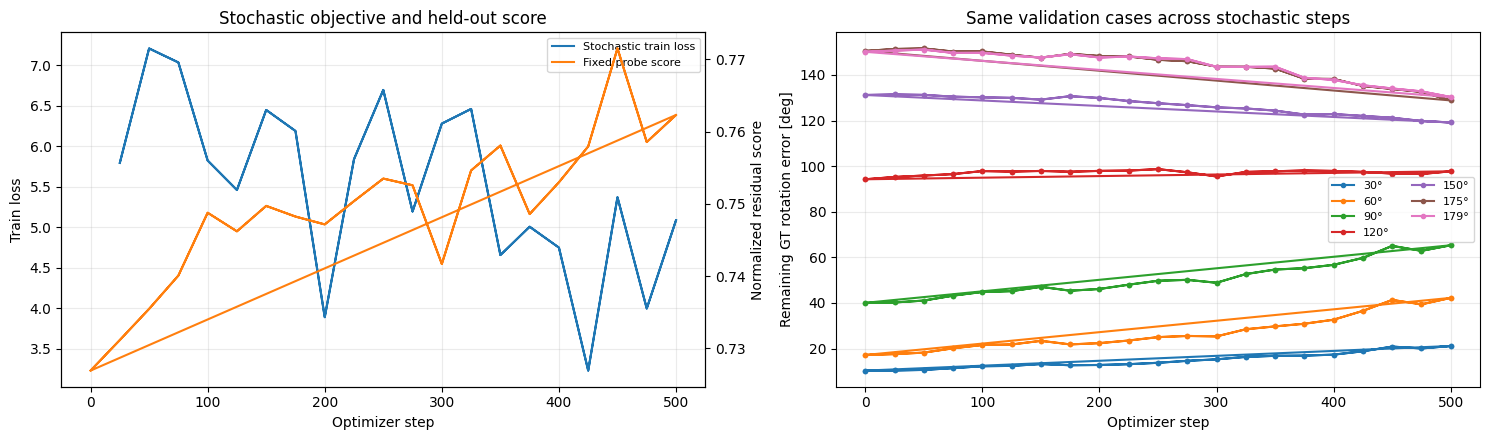

In [18]:
if stochastic_history:
    pd.DataFrame(stochastic_history).to_csv(RUN_DIR / 'stochastic_6d_history.csv', index=False)
    pd.DataFrame(stochastic_probe_rows).to_csv(RUN_DIR / 'stochastic_6d_angle_cases.csv', index=False)
    trace = pd.DataFrame(stochastic_history)
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    axes[0].plot(trace.step, trace.train_loss, label='Stochastic train loss')
    ax0 = axes[0].twinx()
    ax0.plot(trace.step, trace.probe_score, color='C1', label='Fixed probe score')
    axes[0].set(xlabel='Optimizer step', ylabel='Train loss', title='Stochastic objective and held-out score')
    ax0.set_ylabel('Normalized residual score')
    h1,l1=axes[0].get_legend_handles_labels();h2,l2=ax0.get_legend_handles_labels();axes[0].legend(h1+h2,l1+l2,fontsize=8)
    for a in PROBE_ANGLES_DEG:
        if a == 0:
            continue
        axes[1].plot(trace.step, trace[f'angle_{int(a)}_deg'], marker='.', label=f'{int(a)}°')
    axes[1].set(xlabel='Optimizer step', ylabel='Remaining GT rotation error [deg]', title='Same validation cases across stochastic steps')
    axes[1].legend(ncol=2,fontsize=8)
    for ax in axes:ax.grid(alpha=.25)
    fig.tight_layout();fig.savefig(RUN_DIR / 'stochastic_6d_learning.png', dpi=170)
    if SHOW_PLOTS:plt.show()
    else:plt.close(fig)


### Stochastic checkpoint vs pretrained 6D baseline

This is the first go/no-go check before full training.

In [19]:
# Compare the best stochastic candidate against the SAME held-out angular cases.
# This cell does not change the main model or its optimizer.
if STOCHASTIC_CANDIDATE_PATH.is_file():
    stochastic_candidate_model = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)
    candidate_state = torch.load(STOCHASTIC_CANDIDATE_PATH, map_location='cpu', weights_only=True)
    stochastic_candidate_model.load_state_dict(candidate_state['model_state_dict'], strict=True)
    candidate_probe_df = evaluate_probe(stochastic_candidate_model, full_probe_batches)
    candidate_probe_summary = print_probe_summary(candidate_probe_df, label=f'Stochastic best, step {candidate_state["step"]}')
    baseline_and_candidate = initial_probe_summary[['angle_deg', 'final_deg']].merge(candidate_probe_summary[['angle_deg', 'final_deg']], on='angle_deg', suffixes=('_baseline', '_candidate'))
    baseline_and_candidate['gain_deg'] = baseline_and_candidate.final_deg_baseline - baseline_and_candidate.final_deg_candidate
    display(baseline_and_candidate.round(3))
    del stochastic_candidate_model, candidate_state
else:
    print('No stochastic candidate saved. Run stochastic preflight before evaluating this cell.')


Stochastic best, step 0 | normalized residual score: 0.6840 | lower is better


,angle_deg,n,before_deg,final_deg,improvement_deg,relative_remaining,fraction_improving,predicted_step_deg,healthy_drift_deg,error_6d
0,0.0,64,0.0,1.245,-1.245,NaN,0.000,1.245,1.194,0.001
1,30.0,64,30.0,10.319,19.681,0.344,0.969,27.542,0.400,0.023
2,60.0,64,60.0,18.540,41.460,0.309,0.984,55.123,0.318,0.070
3,90.0,64,90.0,37.903,52.097,0.421,0.953,72.424,0.310,0.136
4,120.0,64,120.0,84.353,35.647,0.703,0.734,91.974,0.284,0.292
5,150.0,64,150.0,118.357,31.643,0.789,0.641,104.696,0.337,0.368
6,175.0,64,175.0,144.476,30.524,0.826,0.891,109.378,0.343,0.417
7,179.0,64,179.0,146.737,32.263,0.820,0.984,109.854,0.339,0.423


,angle_deg,final_deg_baseline,final_deg_candidate,gain_deg
0,0.0,1.245,1.245,0.0
1,30.0,10.319,10.319,0.0
2,60.0,18.540,18.540,0.0
3,90.0,37.903,37.903,0.0
4,120.0,84.353,84.353,0.0
5,150.0,118.357,118.357,0.0
6,175.0,144.476,144.476,0.0
7,179.0,146.737,146.737,0.0


In [29]:

# Appendix A. Matched, batched rollouts: pretrained 6D baseline vs coarse-tuned 6D (stochastic best or full best).
# Use the same validation cases, sensor keys, rotation axes, static true calibration and chronological windows for both models.

# Rollout from either the best stochastic candidate (default, full training off)
# or the best full-training checkpoint (when RUN_FULL_TRAINING=True).
ROLL58_BASELINE_CHECKPOINT = BASELINE_6D_CHECKPOINT
ROLL58_DATASET = val_dataset
ROLL58_SEQUENCES = tuple(VAL_NAMES)
ROLL58_NUM_WINDOWS = 12
ROLL58_STARTS_PER_SEQUENCE = 2
ROLL58_CALIBRATIONS_PER_START = 8
ROLL58_CALIBRATION_BATCH_SIZE = 4
ROLL58_FAULT_KEYS = ('lidar', 'lidar_right')
ROLL58_ANGLES_DEG = (0.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
ROLL58_UPDATE_ALL_KEYS = True
ROLL58_SEED = VAL_AUG_SEED + 1_900_000

roll58_baseline_model = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)
roll58_tuned_model = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)
load_training_checkpoint(ROLL58_BASELINE_CHECKPOINT, model=roll58_baseline_model, map_location=DEVICE, restore_rng_state=False)
roll58_models = {
    'Baseline 6D': roll58_baseline_model.eval().requires_grad_(False),
    'Coarse-tuned 6D': roll58_tuned_model.eval().requires_grad_(False),
}

def roll58_copy_states(states):
    """Clone calibration tensors so different model rollouts cannot contaminate one another."""
    return {
        key: replace(state, transform=state.transform.detach().clone(), time_offset=state.time_offset.detach().clone())
        for key, state in states.items()
    }


def roll58_repeat_tensor(value, copies):
    """Repeat the batch dimension of a single-window tensor, preserving dtype and device."""
    if value is None or not torch.is_tensor(value) or value.ndim == 0:
        return value
    if value.shape[0] != 1:
        raise ValueError(f'Expected a single-item source batch, got shape {tuple(value.shape)}')
    return value.expand(copies, *value.shape[1:]).clone()


def roll58_repeat_window(window, copies):
    """Make an independent batched copy of one raw physical window before truth augmentation."""
    streams = {
        key: replace(
            stream,
            values=roll58_repeat_tensor(stream.values, copies),
            timestamps=roll58_repeat_tensor(stream.timestamps, copies),
            sample_mask=roll58_repeat_tensor(stream.sample_mask, copies),
            interval_start_timestamps=roll58_repeat_tensor(stream.interval_start_timestamps, copies),
        )
        for key, stream in window.streams.items()
    }

    states = {
        key: replace(
            state,
            transform=roll58_repeat_tensor(state.transform, copies),
            time_offset=roll58_repeat_tensor(state.time_offset, copies),
        )
        for key, state in window.current_calibration.items()
    }

    targets = None if window.targets is None else {
        key: replace(
            target,
            next_transform=roll58_repeat_tensor(target.next_transform, copies),
            next_time_offset=roll58_repeat_tensor(target.next_time_offset, copies),
            change_label=roll58_repeat_tensor(target.change_label, copies),
            change_time=roll58_repeat_tensor(target.change_time, copies),
        )
        for key, target in window.targets.items()
    }

    indices = window.dataset_indices
    if torch.is_tensor(indices) and indices.ndim > 0:
        indices = roll58_repeat_tensor(indices, copies)
    elif isinstance(indices, (tuple, list)) and len(indices) == 1:
        indices = type(indices)(list(indices) * copies)

    return WindowBatch(
        streams=streams,
        current_calibration=states,
        metadata=dict(window.metadata),
        targets=targets,
        dataset_indices=indices,
    )


def roll58_sequence_indices(dataset, sequence, num_windows, num_starts):
    """Return equally spaced chronological blocks from a specific sequence."""
    indices = np.asarray(dataset.window_indices_for_sequence(sequence), dtype=np.int64)
    max_start = len(indices) - num_windows

    if max_start < 0:
        raise ValueError(f'{sequence}: {len(indices)} windows available but {num_windows} requested')

    starts = np.unique(np.linspace(0, max_start, min(num_starts, max_start + 1)).round().astype(int))
    return [indices[start:start + num_windows] for start in starts]


@torch.inference_mode()
def roll58_physical_sequence(indices, physical_seed, batch_size):
    """Generate distinct true calibrations per batch item, constant through all chronological windows.

    Each chronological raw window is repeated before augmentation. Reinitializing the truth
    generator with the same seed for each window guarantees that case j has the same physically
    consistent true calibration at every time, while different cases j have different truths.
    """
    physical_windows = []
    truth = None

    for index in indices:
        base = window_batch_to(collate_windows([ROLL58_DATASET[int(index)]]), DEVICE, dtype=DTYPE)
        batched = roll58_repeat_window(base, batch_size)
        physical = physical_augmenter(batched, generator=augmentation_generator(physical_seed)).augmented_window

        if truth is None:
            truth = roll58_copy_states(physical.current_calibration)
        else:
            for key in CALIBRATION_KEYS:
                torch.testing.assert_close(physical.current_calibration[key].transform, truth[key].transform, atol=2e-5, rtol=2e-5)
                torch.testing.assert_close(physical.current_calibration[key].time_offset, truth[key].time_offset, atol=2e-6, rtol=2e-6)

        physical_windows.append(physical)

    return physical_windows, truth


@torch.inference_mode()
def roll58_run_comparison():
    """Compare old and fine-tuned 6D predictors across identical complete feedback trajectories."""
    records = []

    for sequence_id, sequence in enumerate(ROLL58_SEQUENCES):
        blocks = roll58_sequence_indices(ROLL58_DATASET, sequence, ROLL58_NUM_WINDOWS, ROLL58_STARTS_PER_SEQUENCE)

        for start_id, indices in enumerate(blocks):
            for batch_start in range(0, ROLL58_CALIBRATIONS_PER_START, ROLL58_CALIBRATION_BATCH_SIZE):
                batch_size = min(ROLL58_CALIBRATION_BATCH_SIZE, ROLL58_CALIBRATIONS_PER_START - batch_start)
                physical_seed = ROLL58_SEED + 1_000_003 * sequence_id + 100_003 * start_id + 1_009 * batch_start

                physical_windows, truth = roll58_physical_sequence(indices, physical_seed, batch_size)

                axis_gen = augmentation_generator(physical_seed + 35_011)
                axes = torch.randn(batch_size, 3, generator=axis_gen, device=DEVICE, dtype=DTYPE)
                axes = axes / torch.linalg.vector_norm(axes, dim=-1, keepdim=True).clamp_min(1e-9)

                for fault_key in ROLL58_FAULT_KEYS:
                    for angle in ROLL58_ANGLES_DEG:
                        xi = {key: torch.zeros(batch_size, 6, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                        tau = {key: torch.zeros(batch_size, 1, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}

                        xi[fault_key][:, :3] = axes * np.deg2rad(float(angle))
                        initial = apply_independent_prior_faults(truth, xi, tau)
                        keys_to_update = CALIBRATION_KEYS if ROLL58_UPDATE_ALL_KEYS else (fault_key,)

                        for model_name, evaluation_model in roll58_models.items():
                            states = roll58_copy_states(initial)

                            for step in range(ROLL58_NUM_WINDOWS + 1):
                                active_error = rotation_geodesic_deg(
                                    states[fault_key].transform[:, :3, :3],
                                    truth[fault_key].transform[:, :3, :3],
                                ).detach().cpu().numpy()

                                healthy_errors = torch.stack([
                                    rotation_geodesic_deg(
                                        states[key].transform[:, :3, :3],
                                        truth[key].transform[:, :3, :3],
                                    )
                                    for key in CALIBRATION_KEYS if key != fault_key
                                ], dim=0).mean(dim=0).detach().cpu().numpy()

                                for j in range(batch_size):
                                    records.append(dict(
                                        sequence=sequence,
                                        start_index=int(indices[0]),
                                        calibration_id=int(batch_start + j),
                                        physical_seed=int(physical_seed),
                                        fault_key=fault_key,
                                        angle_deg=float(angle),
                                        model=model_name,
                                        step=step,
                                        elapsed_s=step * WINDOW_STRIDE_S,
                                        axis_x=float(axes[j, 0]),
                                        axis_y=float(axes[j, 1]),
                                        axis_z=float(axes[j, 2]),
                                        active_error_deg=float(active_error[j]),
                                        healthy_error_deg=float(healthy_errors[j]),
                                    ))

                                if step == ROLL58_NUM_WINDOWS:
                                    break

                                input_window = clone_with_current_calibration(physical_windows[step], states)
                                prediction = model_predictions(input_window, model_override=evaluation_model).predictions

                                states = apply_calibration_6d_update(states, prediction, keys_to_update=keys_to_update)

            print(
                f'Completed {sequence} start {start_id + 1}/{len(blocks)} '
                f'({ROLL58_CALIBRATIONS_PER_START} calibrations, {len(ROLL58_FAULT_KEYS)} fault keys)',
                flush=True,
            )

    return pd.DataFrame.from_records(records)



Baseline checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.27_full_rotation_regression/best.pt
Stochastic checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.28_coarse_120_179_finetune/stochastic_last_6d_state.pt
Stochastic step: 500


/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Completed Urban26 start 1/2 (8 calibrations, 2 fault keys)
Completed Urban26 start 2/2 (8 calibrations, 2 fault keys)
Completed Urban28 start 1/2 (8 calibrations, 2 fault keys)
Completed Urban28 start 2/2 (8 calibrations, 2 fault keys)


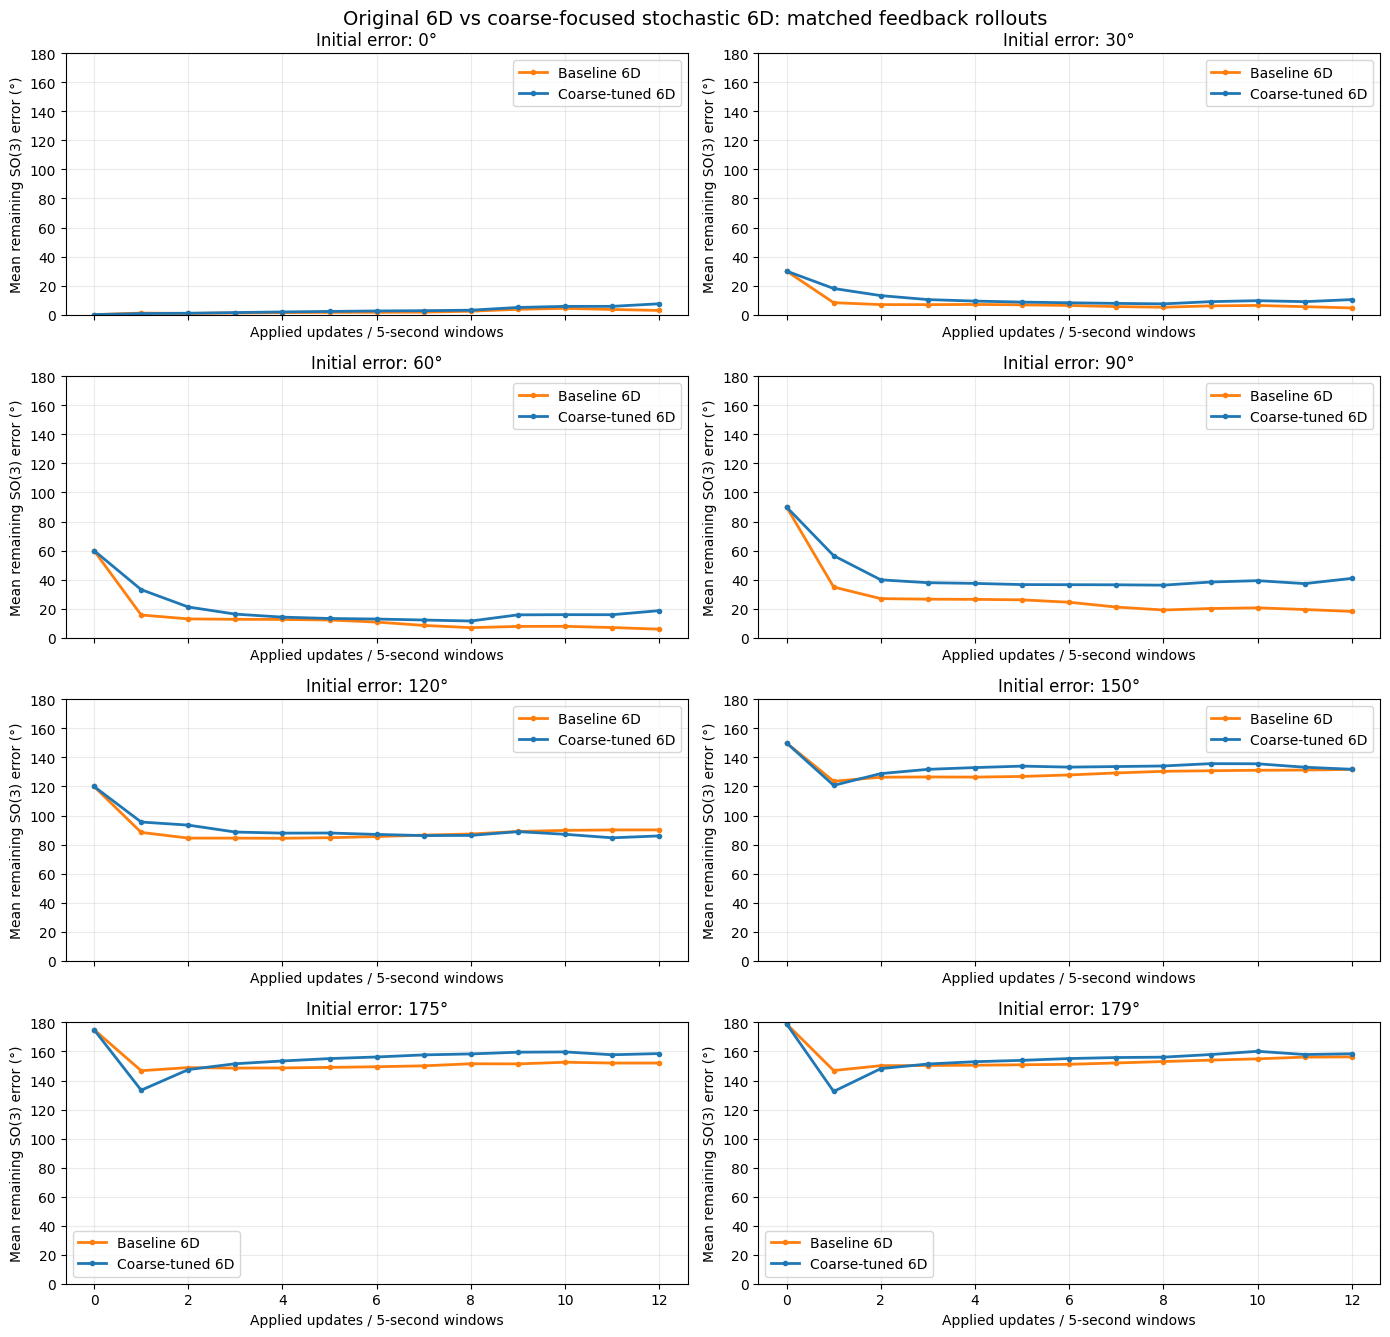

,angle_deg,model,n_cases,mean_error_deg,median_error_deg,p90_error_deg,fraction_below_10deg,fraction_below_30deg
12,0.0,Baseline 6D,64,2.868,2.622,6.710,1.000,1.000
25,0.0,Coarse-tuned 6D,64,7.470,4.379,29.258,0.875,1.000
38,30.0,Baseline 6D,64,4.597,3.254,7.230,0.953,1.000
51,30.0,Coarse-tuned 6D,64,10.351,7.919,23.733,0.672,0.969
64,60.0,Baseline 6D,64,5.826,3.493,14.052,0.844,1.000
77,60.0,Coarse-tuned 6D,64,18.614,7.827,29.719,0.625,0.891
90,90.0,Baseline 6D,64,18.081,5.802,36.587,0.688,0.875
103,90.0,Coarse-tuned 6D,64,40.828,9.100,164.525,0.531,0.766
116,120.0,Baseline 6D,64,90.095,122.409,178.003,0.453,0.484
129,120.0,Coarse-tuned 6D,64,85.969,33.780,178.746,0.281,0.484


In [30]:

# Appendix C. Original 6D vs final coarse-trained stochastic 6D.
# Requires the helper definitions from Appendix A.

STOCHASTIC_LAST_PATH = RUN_DIR / "stochastic_last_6d_state.pt"
if not STOCHASTIC_LAST_PATH.is_file():
    raise FileNotFoundError(f"Final stochastic checkpoint not found: {STOCHASTIC_LAST_PATH}")

# Load both models explicitly.
load_training_checkpoint(BASELINE_6D_CHECKPOINT, model=roll58_baseline_model, map_location=DEVICE, restore_rng_state=False)

stochastic_checkpoint = torch.load(STOCHASTIC_LAST_PATH, map_location="cpu", weights_only=True)
roll58_tuned_model.load_state_dict(stochastic_checkpoint["model_state_dict"], strict=True)

roll58_models = {
    "Baseline 6D": roll58_baseline_model.eval().requires_grad_(False),
    "Coarse-tuned 6D": roll58_tuned_model.eval().requires_grad_(False),
}

ROLL58_OUTPUT_DIR = RUN_DIR / "plots" / "rollout_stochastic_last_vs_original"
ROLL58_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Baseline checkpoint:", BASELINE_6D_CHECKPOINT)
print("Stochastic checkpoint:", STOCHASTIC_LAST_PATH)
print("Stochastic step:", stochastic_checkpoint["step"])

# Run both models on identical chronological windows, true calibrations and fault axes.
stochastic_rollout_df = roll58_run_comparison()

stochastic_rollout_summary = (
    stochastic_rollout_df
    .groupby(["angle_deg", "model", "step"], as_index=False)
    .agg(
        mean_error_deg=("active_error_deg", "mean"),
        median_error_deg=("active_error_deg", "median"),
        p90_error_deg=("active_error_deg", lambda x: x.quantile(0.90)),
        fraction_below_10deg=("active_error_deg", lambda x: (x < 10.0).mean()),
        fraction_below_30deg=("active_error_deg", lambda x: (x < 30.0).mean()),
        n_cases=("active_error_deg", "size"),
    )
)

stochastic_rollout_df.to_csv(ROLL58_OUTPUT_DIR / "individual_rollouts.csv", index=False)
stochastic_rollout_summary.to_csv(ROLL58_OUTPUT_DIR / "rollout_summary.csv", index=False)

# Plot one subplot per angle with exactly two mean curves.
ncols = 2
nrows = math.ceil(len(ROLL58_ANGLES_DEG) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.4 * nrows), squeeze=False, sharex=True)

colors = {
    "Baseline 6D": "tab:orange",
    "Coarse-tuned 6D": "tab:blue",
}

for ax, angle in zip(axes.flat, ROLL58_ANGLES_DEG):
    for model_name in ("Baseline 6D", "Coarse-tuned 6D"):
        curve = stochastic_rollout_summary[
            (stochastic_rollout_summary.angle_deg == angle)
            & (stochastic_rollout_summary.model == model_name)
        ].sort_values("step")

        ax.plot(
            curve.step,
            curve.mean_error_deg,
            label=model_name,
            color=colors[model_name],
            marker="o",
            markersize=3,
            linewidth=2,
        )

    ax.set(
        title=f"Initial error: {angle:g}°",
        xlabel="Applied updates / 5-second windows",
        ylabel="Mean remaining SO(3) error (°)",
    )
    ax.set_ylim(0, 180)
    ax.grid(alpha=0.25)
    ax.legend()

for ax in list(axes.flat)[len(ROLL58_ANGLES_DEG):]:
    ax.set_visible(False)

fig.suptitle("Original 6D vs coarse-focused stochastic 6D: matched feedback rollouts", fontsize=14)
fig.tight_layout()
fig.savefig(ROLL58_OUTPUT_DIR / "stochastic_vs_original_rollouts.png", dpi=180)
plt.show()

# Compare the final mean, median and success fractions.
final_summary = stochastic_rollout_summary[
    stochastic_rollout_summary.step == ROLL58_NUM_WINDOWS
]

display(
    final_summary[
        ["angle_deg", "model", "n_cases", "mean_error_deg", "median_error_deg",
         "p90_error_deg", "fraction_below_10deg", "fraction_below_30deg"]
    ].round(3)
)


## 10. Full-training epoch runner and checkpoint initialization

All weights are unfrozen from epoch 1. `ReduceLROnPlateau` responds to **validation supervised loss**. The **best checkpoint** is selected by a fixed-angle, angle-balanced normalized residual score (30°, 90°, 150°, 175°, 179° plus 0° drift), while both metrics are logged. Fixed angular validation uses untouched held-out KAIST sequences, not the test split.

In [31]:
def run_6d_epoch(loader, *, training, generator, max_batches=None):
    model.train(training)
    sums, counts = defaultdict(float), defaultdict(float)
    n_samples, optimizer_updates = 0, 0
    pending_samples, pending_microbatches = 0, 0
    started = time.perf_counter()
    if training:
        optimizer.zero_grad(set_to_none=True)

    def optimizer_flush():
        nonlocal pending_samples, pending_microbatches, optimizer_updates
        if pending_samples == 0:
            return
        for p in model.parameters():
            if p.grad is not None:
                p.grad.div_(pending_samples)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
        optimizer.step()
        optimizer.zero_grad(set_to_none=True)
        optimizer_updates += 1
        pending_samples, pending_microbatches = 0, 0

    with (torch.enable_grad() if training else torch.no_grad()):
        for batch_id, cpu_batch in enumerate(loader):
            if max_batches is not None and batch_id >= max_batches:
                break
            base = window_batch_to(cpu_batch, DEVICE, dtype=DTYPE)
            augmented = make_training_window(base, generator=generator)
            prediction = model_predictions(augmented)
            loss, metrics = compute_6d_objective(augmented, prediction)
            n = len(next(iter(augmented.current_calibration.values())).transform)
            if training:
                (loss * n).backward()
                pending_samples += n
                pending_microbatches += 1
                if pending_microbatches >= GRADIENT_ACCUMULATION_STEPS:
                    optimizer_flush()
            for key, value in metrics.items():
                if key == 'active_rotation_count':
                    continue
                sums[key] += float(value) * n
                counts[key] += n
            n_samples += n
            del base, augmented, prediction, loss
        if training:
            optimizer_flush()
    if not n_samples:
        raise RuntimeError('Epoch used no samples')
    result = metric_average(sums, counts)
    result.update(n_samples=n_samples, optimizer_updates=optimizer_updates, elapsed_s=time.perf_counter()-started)
    
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return result


BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH = RUN_DIR / 'best.pt', RUN_DIR / 'last.pt'
HISTORY_PATH = RUN_DIR / 'training_6d_history.csv'
checkpoint_config = dict(run_name=RUN_NAME, architecture='PooledCalibration6DModel', calibration_keys=CALIBRATION_KEYS, source_checkpoint=str(INIT_6D_CHECKPOINT), head_mlp_lr=HEAD_MLP_LR, transformer_lr=TRANSFORMER_LR, batch_size=BATCH_SIZE, gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS, loss_weights=asdict(LOSS_WEIGHTS), active_weight=ACTIVE_ROTATION_SUPERVISION_WEIGHT, fine_max_deg=FINE_ROTATION_MAX_DEG, coarse_range_deg=(COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG), coarse_probability=COARSE_PRIOR_PROBABILITY, translation_prior_m=PRIOR_TRANSLATION_MAX_M, tau_reference_s=REFINED_TAU_BY_SENSOR_S, train_names=tuple(TRAIN_NAMES), val_names=tuple(VAL_NAMES), probe_angles=PROBE_ANGLES_DEG, probe_windows=PROBE_WINDOWS, probe_score_angles=PROBE_SCORE_ANGLES_DEG, coarse_probe_score_weight=PROBE_COARSE_SCORE_WEIGHT, zero_drift_weight=ZERO_DRIFT_WEIGHT)
train_generator = augmentation_generator(TRAIN_AUG_SEED)
start_epoch, global_step, best_score, best_epoch = 0, 0, float('inf'), 0
history=[]
if RESUME_FULL_TRAINING:
    if not LAST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(LAST_CHECKPOINT_PATH)
    metadata = torch.load(LAST_CHECKPOINT_PATH, map_location='cpu', weights_only=False)
    extra = metadata.get('extra_state') or {}
    if extra.get('config_6d') != checkpoint_config:
        raise RuntimeError('6D resume configuration differs; use a new RUN_NAME rather than resuming')
    loaded = load_training_checkpoint(LAST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler, generators={'train_shuffle': train_shuffle_generator, 'train_aug': train_generator}, map_location=DEVICE, restore_rng_state=True)
    start_epoch, global_step = int(loaded.get('epoch', 0)), int(loaded.get('global_step', 0))
    best_score, best_epoch = float(extra['best_probe_score']), int(extra.get('best_epoch',0))
    if HISTORY_PATH.is_file():
        history=pd.read_csv(HISTORY_PATH).to_dict('records')
    print('Resumed exact 6D run at epoch', start_epoch)
else:
    if RUN_FULL_TRAINING and any(p.exists() for p in (BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH, HISTORY_PATH)):
        raise FileExistsError('Run files already exist; choose a new RUN_NAME or RESUME_FULL_TRAINING=True')
    if LOAD_STOCHASTIC_CANDIDATE_FOR_FULL:
        if not STOCHASTIC_CANDIDATE_PATH.is_file():
            raise FileNotFoundError(STOCHASTIC_CANDIDATE_PATH)
        candidate = torch.load(STOCHASTIC_CANDIDATE_PATH, map_location='cpu', weights_only=True)
        model.load_state_dict(candidate['model_state_dict'], strict=True)
        print('Explicitly initialized from stochastic candidate step', candidate['step'])
    else:
        print('Initialized full run from best pre-trained 6D checkpoint (preflight restored).')


def save_6d_checkpoint(path, epoch, metrics):
    save_training_checkpoint(path, model=model, optimizer=optimizer, scheduler=scheduler, epoch=epoch, global_step=global_step, metrics=metrics, generators={'train_shuffle':train_shuffle_generator, 'train_aug':train_generator}, extra_state={'config_6d': checkpoint_config, 'best_probe_score':best_score, 'best_epoch':best_epoch})


Initialized full run from best pre-trained 6D checkpoint (preflight restored).


## 11. Optional full fine-tuning, with fine and coarse angle probes every epoch

In [32]:

if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

In [33]:
if RUN_FULL_TRAINING:
    for epoch in range(start_epoch, NUM_EPOCHS):
        train_shuffle_generator.manual_seed(RANDOM_SEED + 12001 + epoch)
        train = run_6d_epoch(train_loader, training=True, generator=train_generator, max_batches=MAX_TRAIN_BATCHES_PER_EPOCH)
        val = run_6d_epoch(val_loader, training=False, generator=augmentation_generator(VAL_AUG_SEED), max_batches=MAX_VAL_BATCHES_PER_EPOCH)
        scheduler.step(val['loss_total'])
        global_step += train['optimizer_updates']
        improved = False
        row = dict(epoch=epoch+1, global_step=global_step, train_loss=train['loss_total'], val_loss=val['loss_total'], train_rotation_6d=train['loss_rotation_6d'], val_rotation_6d=val['loss_rotation_6d'], train_rotation_chordal=train['loss_rotation_chordal'], val_rotation_chordal=val['loss_rotation_chordal'], train_translation=train['loss_translation'], val_translation=val['loss_translation'], train_tau=train['loss_tau'], val_tau=val['loss_tau'], train_active_deg=train['active_rotation_error_deg'], val_active_deg=val['active_rotation_error_deg'], head_mlp_lr=optimizer.param_groups[1]['lr'], transformer_lr=optimizer.param_groups[0]['lr'])
        if (epoch+1) % PROBE_EVERY_EPOCHS == 0:
            probe = evaluate_probe(model, full_probe_batches)
            summary = summarize_probe(probe)
            score = probe_score(summary)
            row['probe_score'] = score
            for angle in PROBE_ANGLES_DEG:
                sub=summary.loc[summary.angle_deg==angle].iloc[0]
                row[f'probe_{int(angle)}_final_deg'] = float(sub.final_deg)
                row[f'probe_{int(angle)}_improves'] = float(sub.fraction_improving)
            if score < best_score:
                improved = True
                best_score, best_epoch = score, epoch+1
                save_6d_checkpoint(BEST_CHECKPOINT_PATH, epoch+1, row)
                # print('New best angular probe checkpoint at epoch', best_epoch, '| score',round(score,4))
        history.append(row)
        pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
        save_6d_checkpoint(LAST_CHECKPOINT_PATH, epoch+1, row)
        angles_report=', '.join(f'{int(a)}°={row[f"probe_{int(a)}_final_deg"]:.1f}°' for a in (0.0,30.0,90.0,120.0,150.0,175.0,179.0)) if 'probe_score' in row else 'not evaluated'
        print(f'Epoch {epoch+1:3d}/{NUM_EPOCHS} train={train["loss_total"]:.4f} val={val["loss_total"]:.4f} | fixed probe: {angles_report} | LR={row["head_mlp_lr"]:.1e}/{row["transformer_lr"]:.1e}'+ (" BEST" if improved else ""), flush=True)
else:
    print('Full training disabled.')


Epoch   1/50 train=5.5028 val=5.4693 | fixed probe: 0°=1.5°, 30°=14.7°, 90°=45.4°, 120°=86.5°, 150°=114.2°, 175°=136.2°, 179°=138.0° | LR=5.0e-05/5.0e-06 BEST
Epoch   2/50 train=5.3491 val=5.2762 | fixed probe: 0°=1.8°, 30°=20.0°, 90°=54.9°, 120°=88.7°, 150°=107.9°, 175°=126.4°, 179°=128.5° | LR=5.0e-05/5.0e-06
Epoch   3/50 train=5.1730 val=5.1501 | fixed probe: 0°=1.6°, 30°=24.6°, 90°=65.1°, 120°=92.7°, 150°=103.3°, 175°=120.0°, 179°=121.6° | LR=5.0e-05/5.0e-06
Epoch   4/50 train=5.1926 val=5.0301 | fixed probe: 0°=2.0°, 30°=28.5°, 90°=76.7°, 120°=97.0°, 150°=101.6°, 175°=117.4°, 179°=118.3° | LR=5.0e-05/5.0e-06
Epoch   5/50 train=5.2004 val=4.9234 | fixed probe: 0°=2.0°, 30°=27.7°, 90°=77.8°, 120°=95.7°, 150°=98.8°, 175°=111.8°, 179°=111.8° | LR=5.0e-05/5.0e-06
Epoch   6/50 train=5.0738 val=4.8670 | fixed probe: 0°=1.9°, 30°=24.2°, 90°=78.7°, 120°=97.5°, 150°=96.3°, 175°=108.7°, 179°=108.3° | LR=5.0e-05/5.0e-06
Epoch   7/50 train=4.8921 val=4.7687 | fixed probe: 0°=2.2°, 30°=29.2°, 9

KeyboardInterrupt: 

## 12. Full-run learning curves and per-angle history

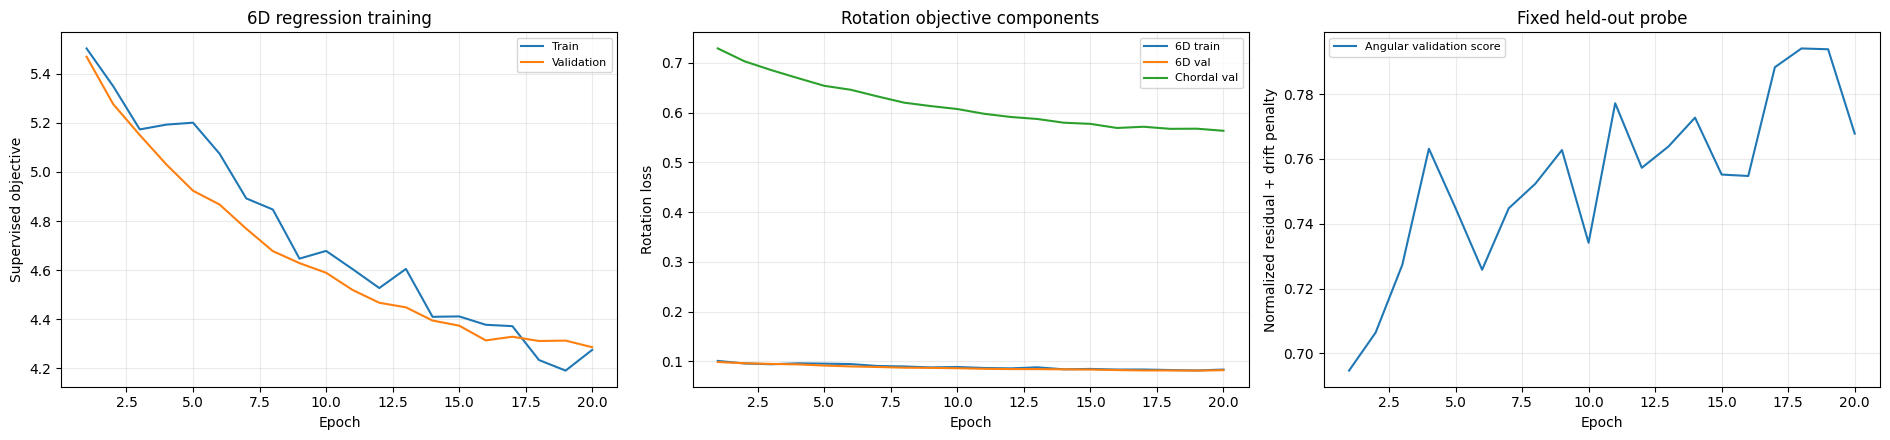

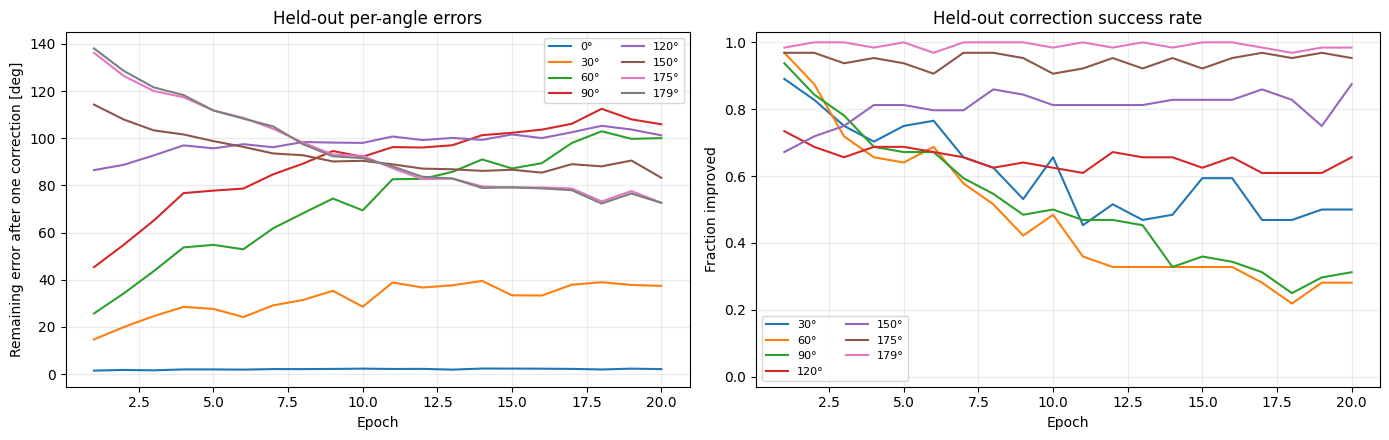

In [34]:
if HISTORY_PATH.is_file():
    train_history = pd.read_csv(HISTORY_PATH)
    fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
    axes[0].plot(train_history.epoch, train_history.train_loss, label='Train')
    axes[0].plot(train_history.epoch, train_history.val_loss, label='Validation')
    axes[0].set(xlabel='Epoch',ylabel='Supervised objective',title='6D regression training')
    axes[1].plot(train_history.epoch, train_history.train_rotation_6d, label='6D train')
    axes[1].plot(train_history.epoch, train_history.val_rotation_6d, label='6D val')
    axes[1].plot(train_history.epoch, train_history.val_rotation_chordal, label='Chordal val')
    axes[1].set(xlabel='Epoch',ylabel='Rotation loss',title='Rotation objective components')
    axes[2].plot(train_history.epoch, train_history.probe_score, label='Angular validation score')
    axes[2].set(xlabel='Epoch',ylabel='Normalized residual + drift penalty',title='Fixed held-out probe')
    for ax in axes:ax.grid(alpha=.25);ax.legend(fontsize=8)
    fig.tight_layout();fig.savefig(RUN_DIR / '6d_training_objectives.png',dpi=170)
    if SHOW_PLOTS:plt.show()
    else:plt.close(fig)

    fig, axes=plt.subplots(1, 2, figsize=(14, 4.5))
    for a in PROBE_ANGLES_DEG:
        axes[0].plot(train_history.epoch, train_history[f'probe_{int(a)}_final_deg'],label=f'{int(a)}°')
    axes[0].set(xlabel='Epoch',ylabel='Remaining error after one correction [deg]',title='Held-out per-angle errors')
    for a in PROBE_ANGLES_DEG:
        if a == 0:continue
        axes[1].plot(train_history.epoch, train_history[f'probe_{int(a)}_improves'],label=f'{int(a)}°')
    axes[1].set(xlabel='Epoch',ylabel='Fraction improved',ylim=(-0.03,1.03),title='Held-out correction success rate')
    for ax in axes:ax.grid(alpha=.25);ax.legend(ncol=2,fontsize=8)
    fig.tight_layout();fig.savefig(RUN_DIR / '6d_training_angles.png',dpi=170)
    if SHOW_PLOTS:plt.show()
    else:plt.close(fig)
else:
    print('No full training history yet.')


## 13. Fine-tuned checkpoint versus starting 6D model, paired on identical faults

The baseline is the **same pretrained encoder with the identity-initialized 6D head** (not the legacy 7D model). This isolates what the 6D training learned. A separate comparison against older regressors/FM can be added afterward using their respective prediction/update adapters.

Best 6D checkpoint | normalized residual score: 0.7678 | lower is better


,angle_deg,n,before_deg,final_deg,improvement_deg,relative_remaining,fraction_improving,predicted_step_deg,healthy_drift_deg,error_6d
0,0.0,64,0.0,2.151,-2.151,NaN,0.000,2.151,1.456,0.007
1,30.0,64,30.0,37.430,-7.430,1.248,0.500,31.823,0.755,0.104
2,60.0,64,60.0,100.032,-40.032,1.667,0.281,101.873,0.530,0.278
3,90.0,64,90.0,105.903,-15.903,1.177,0.312,130.689,0.471,0.325
4,120.0,64,120.0,101.223,18.777,0.844,0.656,148.999,0.412,0.315
5,150.0,64,150.0,83.230,66.770,0.555,0.875,150.666,0.470,0.269
6,175.0,64,175.0,72.661,102.339,0.415,0.953,151.872,0.638,0.240
7,179.0,64,179.0,72.592,106.408,0.406,0.984,152.579,0.701,0.239


Paired residual reduction (positive is better):


,mean,median,std,count
angle_deg,,,,
0.0,-0.906,-1.000,1.325,64
30.0,-27.111,-21.182,24.154,64
60.0,-81.492,-85.418,51.417,64
90.0,-68.000,-82.288,54.796,64
120.0,-16.870,-8.975,66.218,64
150.0,35.127,44.107,68.342,64
175.0,71.815,74.352,59.818,64
179.0,74.146,83.495,57.740,64


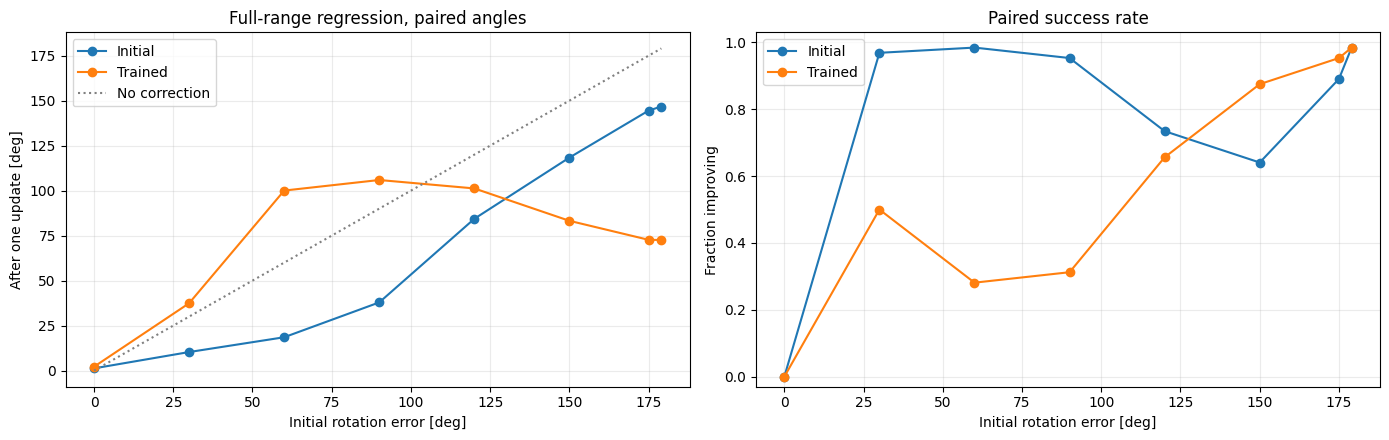

In [35]:
if LAST_CHECKPOINT_PATH.is_file():
    model.eval()
    previous = {key:value.detach().cpu().clone() for key,value in model.state_dict().items()}
    try:
        load_training_checkpoint(LAST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
        best_probe_df = evaluate_probe(model, full_probe_batches)
        best_probe_summary = print_probe_summary(best_probe_df, label='Best 6D checkpoint')
        paired = initial_probe_df.merge(best_probe_df, on=['angle_deg','physical_index','axis_seed','fault_key'], suffixes=('_initial','_trained'),validate='one_to_one')
        paired['error_gain_deg'] = paired.after_deg_initial - paired.after_deg_trained
        print('Paired residual reduction (positive is better):')
        display(paired.groupby('angle_deg').error_gain_deg.agg(['mean','median','std','count']).round(3))
        best_probe_df.to_csv(RUN_DIR/'best_6d_angle_cases.csv',index=False)
        paired.to_csv(RUN_DIR/'paired_initial_vs_trained_6d.csv',index=False)
        fig,axes=plt.subplots(1,2,figsize=(14,4.5))
        for label,sub in [('Initial',initial_probe_summary),('Trained',best_probe_summary)]:
            axes[0].plot(sub.angle_deg,sub.final_deg,marker='o',label=label)
            axes[1].plot(sub.angle_deg,sub.fraction_improving,marker='o',label=label)
        axes[0].plot(PROBE_ANGLES_DEG,PROBE_ANGLES_DEG,linestyle=':',color='gray',label='No correction')
        axes[0].set(xlabel='Initial rotation error [deg]',ylabel='After one update [deg]',title='Full-range regression, paired angles')
        axes[1].set(xlabel='Initial rotation error [deg]',ylabel='Fraction improving',ylim=(-0.03,1.03),title='Paired success rate')
        for ax in axes:ax.grid(alpha=.25);ax.legend()
        fig.tight_layout();fig.savefig(RUN_DIR/'best_6d_angle_comparison.png',dpi=170)
        if SHOW_PLOTS:plt.show()
        else:plt.close(fig)
    finally:
        model.load_state_dict(previous,strict=True)
        del previous
else:
    print('No best checkpoint available yet.')


## 14. Optional final test-split evaluation

Disabled by default. Only evaluate Urban38/Urban39 after you have selected the final checkpoint on the validation split. This cell is unrelated to stochastic preflight.


In [36]:
if RUN_FINAL_TEST_EVALUATION:
    if not LAST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(LAST_CHECKPOINT_PATH)
    previous = {key:value.detach().cpu().clone() for key,value in model.state_dict().items()}
    try:
        load_training_checkpoint(LAST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
        test_probe_batches = build_probe_batches(test_dataset, n_windows=PROBE_WINDOWS, batch_size=PROBE_BATCH_SIZE, seed=TEST_AUG_SEED + 100000, axis_seeds=PROBE_AXIS_SEEDS)
        test_probe_frame = evaluate_probe(model, test_probe_batches)
        print_probe_summary(test_probe_frame, label='FINAL TEST: 6D checkpoint')
        test_probe_frame.to_csv(RUN_DIR / 'final_test_6d_angle_cases.csv',index=False)
    finally:
        model.load_state_dict(previous,strict=True)
        del previous
else:
    print('Test split untouched. Set RUN_FINAL_TEST_EVALUATION=True only for the final comparison.')


Test split untouched. Set RUN_FINAL_TEST_EVALUATION=True only for the final comparison.


## 15. Interpretation and next decisions

- First inspect stochastic fine/coarse probes and the paired 6D feedback rollouts below. Do not start full training solely because the stochastic objective falls.
- Fine-angle drift (0–60°) and coarse-angle recovery (120–179°) must be evaluated together.
- Compare median error, mean error and fraction of rollouts below 10° / 30°: a small mean at 179° can hide a majority of failures.
- The full training run uses exactly the same mixed prior sampling, objective and learning-rate ratio as the stochastic preflight.
- If enabling full training later, set `RUN_FULL_TRAINING=True`, keep `RESUME_FULL_TRAINING=False` for the first run, and restart the notebook from the top. The preflight restores the baseline checkpoint by default.
- No topology, artificial sensor noise, Flow Matching or bounded step target is used.


In [37]:
print('Run:', RUN_DIR)
print('Model: PooledCalibration6DModel | 6 rotation + 3 translation + 1 tau')
print('Full pretrained 6D checkpoint:', INIT_6D_CHECKPOINT)
print('All trainable:', all(p.requires_grad for p in model.parameters()))
print('Optimizer LRs:', [(group['name'], group['lr']) for group in optimizer.param_groups])
print('Stochastic candidate:', STOCHASTIC_CANDIDATE_PATH, '| exists:', STOCHASTIC_CANDIDATE_PATH.is_file())
print('Best full-run checkpoint:', BEST_CHECKPOINT_PATH, '| exists:', BEST_CHECKPOINT_PATH.is_file())
print('Training history:', HISTORY_PATH)


Run: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.28_coarse_120_179_finetune
Model: PooledCalibration6DModel | 6 rotation + 3 translation + 1 tau
Full pretrained 6D checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.27_full_rotation_regression/best.pt
All trainable: True
Optimizer LRs: [('transformer', 5e-06), ('pooler_mlp_head', 5e-05)]
Stochastic candidate: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.28_coarse_120_179_finetune/stochastic_best_6d_state.pt | exists: True
Best full-run checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.28_coarse_120_179_finetune/best.pt | exists: True
Training history: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.28_coarse_120_179_finetune/training_6d_history.csv


## 16. Matched chronological rollouts on 64 randomized calibrations per angle

Runs on **validation sequences only**, matching the exact same static true calibrations, fault axes and physical windows across both **Baseline 6D** (Notebook 57 best checkpoint) and **Coarse-tuned 6D** (best stochastic checkpoint by default; best full checkpoint if full training is enabled). It tests both **0–90°** and **120–179°** initial errors, over 12 sequential 5-second windows. Each subplot shows just two mean trajectories, with optional shaded IQR.

The benchmark deliberately uses one initial faulted sensor and can update all sensors or only the faulted one. Statistics include mean, median, p90, fractions below 10° and 30°, and healthy sensor drift. The reference calibration stays physically constant throughout each trajectory.


In [38]:

# Appendix A. Matched, batched rollouts: pretrained 6D baseline vs coarse-tuned 6D (stochastic best or full best).
# Use the same validation cases, sensor keys, rotation axes, static true calibration and chronological windows for both models.

# Rollout from either the best stochastic candidate (default, full training off)
# or the best full-training checkpoint (when RUN_FULL_TRAINING=True).
ROLL58_BASELINE_CHECKPOINT = BASELINE_6D_CHECKPOINT
ROLL58_USE_FULL_BEST = RUN_FULL_TRAINING and LAST_CHECKPOINT_PATH.is_file()
ROLL58_TUNED_CHECKPOINT = LAST_CHECKPOINT_PATH if ROLL58_USE_FULL_BEST else STOCHASTIC_CANDIDATE_PATH
ROLL58_DATASET = val_dataset
ROLL58_SEQUENCES = tuple(VAL_NAMES)
ROLL58_NUM_WINDOWS = 12
ROLL58_STARTS_PER_SEQUENCE = 2
ROLL58_CALIBRATIONS_PER_START = 8
ROLL58_CALIBRATION_BATCH_SIZE = 4
ROLL58_FAULT_KEYS = ('lidar', 'lidar_right')
ROLL58_ANGLES_DEG = (0.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
ROLL58_UPDATE_ALL_KEYS = True
ROLL58_SEED = VAL_AUG_SEED + 1_900_000
ROLL58_OUTPUT_DIR = RUN_DIR / 'plots' / ('rollout_full_vs_initial' if ROLL58_USE_FULL_BEST else 'rollout_stochastic_vs_initial')
ROLL58_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for path in (ROLL58_BASELINE_CHECKPOINT, ROLL58_TUNED_CHECKPOINT):
    if not path.is_file():
        raise FileNotFoundError(path)
if not set(ROLL58_FAULT_KEYS).issubset(CALIBRATION_KEYS):
    raise ValueError('Unknown rollout fault keys')

roll58_baseline_model = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)
roll58_tuned_model = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)
load_training_checkpoint(ROLL58_BASELINE_CHECKPOINT, model=roll58_baseline_model, map_location=DEVICE, restore_rng_state=False)
if ROLL58_USE_FULL_BEST:
    load_training_checkpoint(ROLL58_TUNED_CHECKPOINT, model=roll58_tuned_model, map_location=DEVICE, restore_rng_state=False)
else:
    roll58_snapshot = torch.load(ROLL58_TUNED_CHECKPOINT, map_location='cpu', weights_only=True)
    roll58_tuned_model.load_state_dict(roll58_snapshot['model_state_dict'], strict=True)
    print('Stochastic checkpoint step:', roll58_snapshot['step'], '| probe score:', roll58_snapshot['score'])
    del roll58_snapshot

roll58_models = {
    'Baseline 6D': roll58_baseline_model.eval().requires_grad_(False),
    'Coarse-tuned 6D': roll58_tuned_model.eval().requires_grad_(False),
}
print('Baseline 6D:', ROLL58_BASELINE_CHECKPOINT)
print('Fine-tuned 6D:', ROLL58_TUNED_CHECKPOINT)
print('Matched rollout cases per angle per model:', len(ROLL58_SEQUENCES) * ROLL58_STARTS_PER_SEQUENCE * ROLL58_CALIBRATIONS_PER_START * len(ROLL58_FAULT_KEYS))


def roll58_copy_states(states):
    """Clone calibration tensors so different model rollouts cannot contaminate one another."""
    return {
        key: replace(state, transform=state.transform.detach().clone(), time_offset=state.time_offset.detach().clone())
        for key, state in states.items()
    }


def roll58_repeat_tensor(value, copies):
    """Repeat the batch dimension of a single-window tensor, preserving dtype and device."""
    if value is None or not torch.is_tensor(value) or value.ndim == 0:
        return value
    if value.shape[0] != 1:
        raise ValueError(f'Expected a single-item source batch, got shape {tuple(value.shape)}')
    return value.expand(copies, *value.shape[1:]).clone()


def roll58_repeat_window(window, copies):
    """Make an independent batched copy of one raw physical window before truth augmentation."""
    streams = {
        key: replace(
            stream,
            values=roll58_repeat_tensor(stream.values, copies),
            timestamps=roll58_repeat_tensor(stream.timestamps, copies),
            sample_mask=roll58_repeat_tensor(stream.sample_mask, copies),
            interval_start_timestamps=roll58_repeat_tensor(stream.interval_start_timestamps, copies),
        )
        for key, stream in window.streams.items()
    }

    states = {
        key: replace(
            state,
            transform=roll58_repeat_tensor(state.transform, copies),
            time_offset=roll58_repeat_tensor(state.time_offset, copies),
        )
        for key, state in window.current_calibration.items()
    }

    targets = None if window.targets is None else {
        key: replace(
            target,
            next_transform=roll58_repeat_tensor(target.next_transform, copies),
            next_time_offset=roll58_repeat_tensor(target.next_time_offset, copies),
            change_label=roll58_repeat_tensor(target.change_label, copies),
            change_time=roll58_repeat_tensor(target.change_time, copies),
        )
        for key, target in window.targets.items()
    }

    indices = window.dataset_indices
    if torch.is_tensor(indices) and indices.ndim > 0:
        indices = roll58_repeat_tensor(indices, copies)
    elif isinstance(indices, (tuple, list)) and len(indices) == 1:
        indices = type(indices)(list(indices) * copies)

    return WindowBatch(
        streams=streams,
        current_calibration=states,
        metadata=dict(window.metadata),
        targets=targets,
        dataset_indices=indices,
    )


def roll58_sequence_indices(dataset, sequence, num_windows, num_starts):
    """Return equally spaced chronological blocks from a specific sequence."""
    indices = np.asarray(dataset.window_indices_for_sequence(sequence), dtype=np.int64)
    max_start = len(indices) - num_windows

    if max_start < 0:
        raise ValueError(f'{sequence}: {len(indices)} windows available but {num_windows} requested')

    starts = np.unique(np.linspace(0, max_start, min(num_starts, max_start + 1)).round().astype(int))
    return [indices[start:start + num_windows] for start in starts]


@torch.inference_mode()
def roll58_physical_sequence(indices, physical_seed, batch_size):
    """Generate distinct true calibrations per batch item, constant through all chronological windows.

    Each chronological raw window is repeated before augmentation. Reinitializing the truth
    generator with the same seed for each window guarantees that case j has the same physically
    consistent true calibration at every time, while different cases j have different truths.
    """
    physical_windows = []
    truth = None

    for index in indices:
        base = window_batch_to(collate_windows([ROLL58_DATASET[int(index)]]), DEVICE, dtype=DTYPE)
        batched = roll58_repeat_window(base, batch_size)
        physical = physical_augmenter(batched, generator=augmentation_generator(physical_seed)).augmented_window

        if truth is None:
            truth = roll58_copy_states(physical.current_calibration)
        else:
            for key in CALIBRATION_KEYS:
                torch.testing.assert_close(physical.current_calibration[key].transform, truth[key].transform, atol=2e-5, rtol=2e-5)
                torch.testing.assert_close(physical.current_calibration[key].time_offset, truth[key].time_offset, atol=2e-6, rtol=2e-6)

        physical_windows.append(physical)

    return physical_windows, truth


@torch.inference_mode()
def roll58_run_comparison():
    """Compare old and fine-tuned 6D predictors across identical complete feedback trajectories."""
    records = []

    for sequence_id, sequence in enumerate(ROLL58_SEQUENCES):
        blocks = roll58_sequence_indices(ROLL58_DATASET, sequence, ROLL58_NUM_WINDOWS, ROLL58_STARTS_PER_SEQUENCE)

        for start_id, indices in enumerate(blocks):
            for batch_start in range(0, ROLL58_CALIBRATIONS_PER_START, ROLL58_CALIBRATION_BATCH_SIZE):
                batch_size = min(ROLL58_CALIBRATION_BATCH_SIZE, ROLL58_CALIBRATIONS_PER_START - batch_start)
                physical_seed = ROLL58_SEED + 1_000_003 * sequence_id + 100_003 * start_id + 1_009 * batch_start

                physical_windows, truth = roll58_physical_sequence(indices, physical_seed, batch_size)

                axis_gen = augmentation_generator(physical_seed + 35_011)
                axes = torch.randn(batch_size, 3, generator=axis_gen, device=DEVICE, dtype=DTYPE)
                axes = axes / torch.linalg.vector_norm(axes, dim=-1, keepdim=True).clamp_min(1e-9)

                for fault_key in ROLL58_FAULT_KEYS:
                    for angle in ROLL58_ANGLES_DEG:
                        xi = {key: torch.zeros(batch_size, 6, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                        tau = {key: torch.zeros(batch_size, 1, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}

                        xi[fault_key][:, :3] = axes * np.deg2rad(float(angle))
                        initial = apply_independent_prior_faults(truth, xi, tau)
                        keys_to_update = CALIBRATION_KEYS if ROLL58_UPDATE_ALL_KEYS else (fault_key,)

                        for model_name, evaluation_model in roll58_models.items():
                            states = roll58_copy_states(initial)

                            for step in range(ROLL58_NUM_WINDOWS + 1):
                                active_error = rotation_geodesic_deg(
                                    states[fault_key].transform[:, :3, :3],
                                    truth[fault_key].transform[:, :3, :3],
                                ).detach().cpu().numpy()

                                healthy_errors = torch.stack([
                                    rotation_geodesic_deg(
                                        states[key].transform[:, :3, :3],
                                        truth[key].transform[:, :3, :3],
                                    )
                                    for key in CALIBRATION_KEYS if key != fault_key
                                ], dim=0).mean(dim=0).detach().cpu().numpy()

                                for j in range(batch_size):
                                    records.append(dict(
                                        sequence=sequence,
                                        start_index=int(indices[0]),
                                        calibration_id=int(batch_start + j),
                                        physical_seed=int(physical_seed),
                                        fault_key=fault_key,
                                        angle_deg=float(angle),
                                        model=model_name,
                                        step=step,
                                        elapsed_s=step * WINDOW_STRIDE_S,
                                        axis_x=float(axes[j, 0]),
                                        axis_y=float(axes[j, 1]),
                                        axis_z=float(axes[j, 2]),
                                        active_error_deg=float(active_error[j]),
                                        healthy_error_deg=float(healthy_errors[j]),
                                    ))

                                if step == ROLL58_NUM_WINDOWS:
                                    break

                                input_window = clone_with_current_calibration(physical_windows[step], states)
                                prediction = model_predictions(input_window, model_override=evaluation_model).predictions

                                states = apply_calibration_6d_update(states, prediction, keys_to_update=keys_to_update)

            print(
                f'Completed {sequence} start {start_id + 1}/{len(blocks)} '
                f'({ROLL58_CALIBRATIONS_PER_START} calibrations, {len(ROLL58_FAULT_KEYS)} fault keys)',
                flush=True,
            )

    return pd.DataFrame.from_records(records)


roll58_df = roll58_run_comparison()

roll58_df['improving'] = np.where(
    roll58_df.angle_deg > 0.0,
    (roll58_df.active_error_deg < roll58_df.angle_deg - 1e-3).astype(float),
    np.nan,
)

roll58_summary = roll58_df.groupby(['angle_deg', 'model', 'step'], as_index=False).agg(
    mean_error_deg=('active_error_deg', 'mean'),
    median_error_deg=('active_error_deg', 'median'),
    p25_error_deg=('active_error_deg', lambda x: x.quantile(0.25)),
    p75_error_deg=('active_error_deg', lambda x: x.quantile(0.75)),
    p90_error_deg=('active_error_deg', lambda x: x.quantile(0.90)),
    mean_healthy_drift_deg=('healthy_error_deg', 'mean'),
    fraction_improving=('improving', 'mean'),
    fraction_below_10deg=('active_error_deg', lambda x: (x < 10.0).mean()),
    fraction_below_30deg=('active_error_deg', lambda x: (x < 30.0).mean()),
    n_cases=('active_error_deg', 'size'),
)

roll58_df.to_csv(ROLL58_OUTPUT_DIR / 'matched_rollout_individual_trajectories.csv', index=False)
roll58_summary.to_csv(ROLL58_OUTPUT_DIR / 'matched_rollout_mean_quantiles.csv', index=False)

expected = len(ROLL58_SEQUENCES) * ROLL58_STARTS_PER_SEQUENCE * ROLL58_CALIBRATIONS_PER_START * len(ROLL58_FAULT_KEYS)
counts = roll58_summary.n_cases.unique()

if len(counts) != 1 or counts[0] != expected:
    raise AssertionError(f'Unexpected case counts: observed {counts}, expected {expected}. Check sequence start uniqueness.')

print(f'Validated {expected} matched rollout cases per angle and model, each lasting {ROLL58_NUM_WINDOWS} windows.')

selected_steps = sorted(set((0, 1, 3, 6, ROLL58_NUM_WINDOWS)) & set(roll58_summary.step.unique()))

display(
    roll58_summary[roll58_summary.step.isin(selected_steps)]
    .pivot_table(index=['angle_deg', 'model'], columns='step', values='mean_error_deg')
    .round(2)
)

print('Final rollout statistics (mean, median, 90th percentile, improvement probability, success below 10°):')

display(
    roll58_summary[roll58_summary.step == ROLL58_NUM_WINDOWS][[
        'angle_deg', 'model', 'n_cases', 'mean_error_deg', 'median_error_deg',
        'p90_error_deg', 'fraction_improving', 'fraction_below_10deg', 'fraction_below_30deg',
        'mean_healthy_drift_deg',
    ]].round(3)
)

print('Final errors by physical sequence and faulted sensor:')

roll58_by_sequence = (
    roll58_df[roll58_df.step == ROLL58_NUM_WINDOWS]
    .groupby(['sequence', 'fault_key', 'angle_deg', 'model'], as_index=False)
    .agg(
        mean_error_deg=('active_error_deg', 'mean'),
        fraction_improving=('improving', 'mean'),
        n_cases=('active_error_deg', 'size'),
    )
)

roll58_by_sequence.to_csv(ROLL58_OUTPUT_DIR / 'rollout_by_sequence_and_fault.csv', index=False)

display(
    roll58_by_sequence[
        roll58_by_sequence.angle_deg.isin((120.0, 150.0, 175.0, 179.0))
    ].round(3)
)


Baseline 6D: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.27_full_rotation_regression/best.pt
Fine-tuned 6D: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.28_coarse_120_179_finetune/last.pt
Matched rollout cases per angle per model: 64
Completed Urban26 start 1/2 (8 calibrations, 2 fault keys)
Completed Urban26 start 2/2 (8 calibrations, 2 fault keys)
Completed Urban28 start 1/2 (8 calibrations, 2 fault keys)
Completed Urban28 start 2/2 (8 calibrations, 2 fault keys)
Validated 64 matched rollout cases per angle and model, each lasting 12 windows.


step                          0       1       3       6       12
angle_deg model                                                 
0.0       Baseline 6D        0.0    1.06    1.09    1.60    2.87
          Coarse-tuned 6D    0.0    1.73    4.89    7.37   11.02
30.0      Baseline 6D       30.0    8.22    6.87    6.30    4.60
          Coarse-tuned 6D   30.0   38.32   37.88   35.13   34.49
60.0      Baseline 6D       60.0   15.63   12.64   10.72    5.83
          Coarse-tuned 6D   60.0  104.06   86.52   92.19   90.29
90.0      Baseline 6D       90.0   34.86   26.50   24.39   18.08
          Coarse-tuned 6D   90.0  113.60   88.56   85.42   83.29
120.0     Baseline 6D      120.0   88.39   84.43   85.49   90.09
          Coarse-tuned 6D  120.0  113.35  114.40  114.01  112.24
150.0     Baseline 6D      150.0  123.61  126.57  127.95  131.78
          Coarse-tuned 6D  150.0   94.41   91.89   90.27   88.60
175.0     Baseline 6D      175.0  146.76  148.54  149.48  152.02
          Coarse-tuned 6D  175.0   86.31   78.19   77.02   79.31
179.0     Baseline 6D      179.0  146.87  150.33  151.15  156.29
          Coarse-tuned 6D  179.0   84.65   77.41   76.83   79.04

Final rollout statistics (mean, median, 90th percentile, improvement probability, success below 10°):


,angle_deg,model,n_cases,mean_error_deg,median_error_deg,p90_error_deg,fraction_improving,fraction_below_10deg,fraction_below_30deg,mean_healthy_drift_deg
12,0.0,Baseline 6D,64,2.868,2.622,6.710,NaN,1.000,1.000,2.715
25,0.0,Coarse-tuned 6D,64,11.021,9.875,18.683,NaN,0.500,1.000,9.081
38,30.0,Baseline 6D,64,4.597,3.254,7.230,1.000,0.953,1.000,2.741
51,30.0,Coarse-tuned 6D,64,34.493,19.443,56.442,0.672,0.141,0.672,8.385
64,60.0,Baseline 6D,64,5.826,3.493,14.052,1.000,0.844,1.000,2.696
77,60.0,Coarse-tuned 6D,64,90.291,112.469,170.841,0.469,0.062,0.297,8.016
90,90.0,Baseline 6D,64,18.081,5.802,36.587,0.938,0.688,0.875,2.821
103,90.0,Coarse-tuned 6D,64,83.293,63.458,170.708,0.547,0.125,0.375,8.008
116,120.0,Baseline 6D,64,90.095,122.409,178.003,0.500,0.453,0.484,2.873
129,120.0,Coarse-tuned 6D,64,112.238,149.572,173.082,0.375,0.094,0.250,8.192


Final errors by physical sequence and faulted sensor:


,sequence,fault_key,angle_deg,model,mean_error_deg,fraction_improving,n_cases
8,Urban26,lidar,120.0,Baseline 6D,100.433,0.438,16
9,Urban26,lidar,120.0,Coarse-tuned 6D,107.089,0.375,16
10,Urban26,lidar,150.0,Baseline 6D,142.587,0.250,16
11,Urban26,lidar,150.0,Coarse-tuned 6D,66.654,0.875,16
12,Urban26,lidar,175.0,Baseline 6D,152.612,0.500,16
13,Urban26,lidar,175.0,Coarse-tuned 6D,64.009,1.000,16
14,Urban26,lidar,179.0,Baseline 6D,163.907,0.938,16
15,Urban26,lidar,179.0,Coarse-tuned 6D,56.617,1.000,16
24,Urban26,lidar_right,120.0,Baseline 6D,95.529,0.500,16
25,Urban26,lidar_right,120.0,Coarse-tuned 6D,120.315,0.312,16


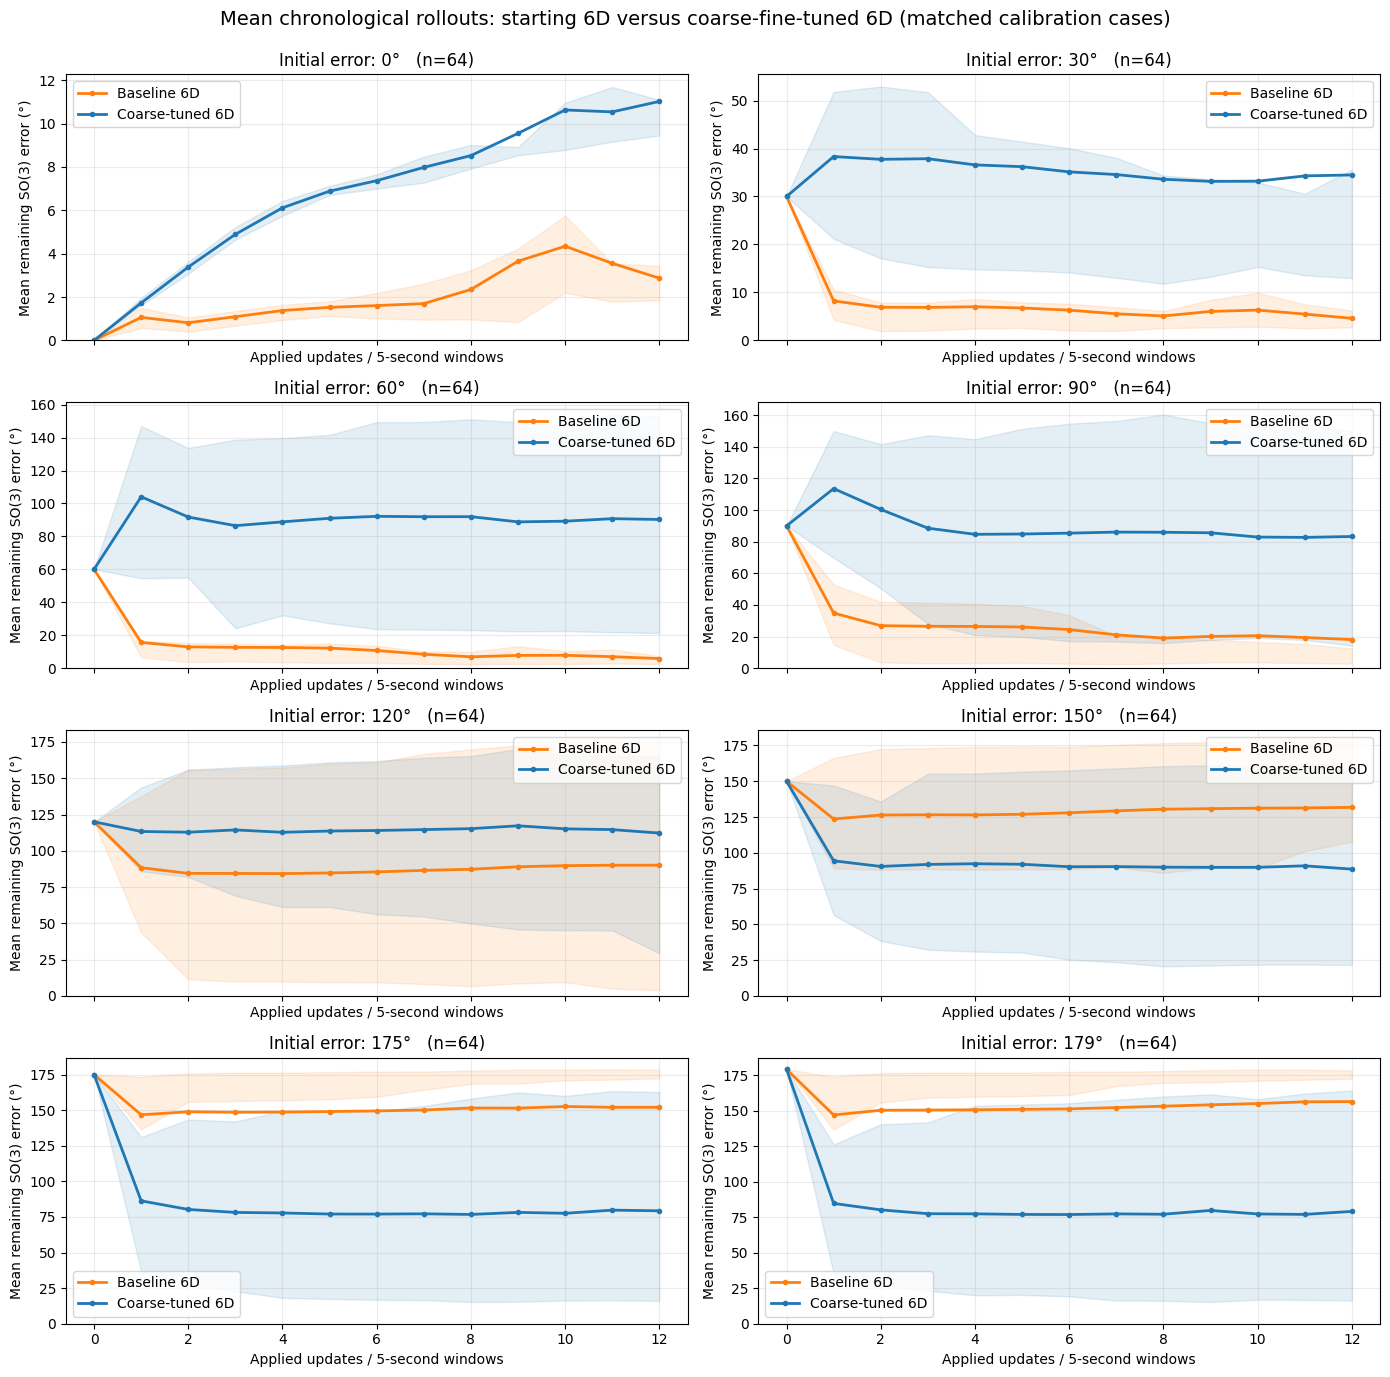

In [39]:

# Appendix B. One subplot per initial fault angle.
# Exactly two lines: starting 6D and coarse-tuned 6D, with optional IQR bands.

ROLL58_PLOT_COLUMNS = 2
ROLL58_SHOW_IQR = True  # Optional shaded 25–75% ranges, still only two mean curves.
ROLL58_MODEL_COLORS = {
    'Baseline 6D': 'tab:orange',
    'Coarse-tuned 6D': 'tab:blue',
}

roll58_num_rows = math.ceil(len(ROLL58_ANGLES_DEG) / ROLL58_PLOT_COLUMNS)

fig, axes = plt.subplots(
    roll58_num_rows,
    ROLL58_PLOT_COLUMNS,
    figsize=(14, 3.5 * roll58_num_rows),
    squeeze=False,
    sharex=True,
)

for ax, angle in zip(axes.flat, ROLL58_ANGLES_DEG):
    for model_name in ('Baseline 6D', 'Coarse-tuned 6D'):
        curve = roll58_summary[
            (roll58_summary.angle_deg == float(angle))
            & (roll58_summary.model == model_name)
        ].sort_values('step')

        if ROLL58_SHOW_IQR:
            ax.fill_between(
                curve.step.to_numpy(),
                curve.p25_error_deg.to_numpy(),
                curve.p75_error_deg.to_numpy(),
                color=ROLL58_MODEL_COLORS[model_name],
                alpha=0.12,
            )

        ax.plot(
            curve.step,
            curve.mean_error_deg,
            marker='o',
            markersize=3,
            linewidth=2,
            color=ROLL58_MODEL_COLORS[model_name],
            label=model_name,
        )

    n_cases = int(curve.n_cases.iloc[0])

    ax.set(
        title=f'Initial error: {angle:g}°   (n={n_cases})',
        xlabel='Applied updates / 5-second windows',
        ylabel='Mean remaining SO(3) error (°)',
    )
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.legend(loc='best')

for ax in list(axes.flat)[len(ROLL58_ANGLES_DEG):]:
    ax.set_visible(False)

fig.suptitle(
    'Mean chronological rollouts: starting 6D versus coarse-fine-tuned 6D (matched calibration cases)',
    fontsize=14,
)

fig.tight_layout(rect=(0, 0, 1, 0.985))
fig.savefig(ROLL58_OUTPUT_DIR / 'baseline_vs_coarse_tuned_6d_mean_by_initial_angle.png', dpi=180)

if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)
